# Proyecto Final · Clasificación de Niveles de Obesidad (Matriz $3 \times 3$)

**Curso:** Aprendizaje Automático · Especialización en Inteligencia Artificial (UAO)  
**Equipo:** Sebastián Giraldo, Violeta España, Luis Murillo, Juan David Velasco y David Vergara  
**Dataset:** *Estimation of Obesity Levels Based on Eating Habits and Physical Condition* (UCI ID `544`)

En este cuaderno seguimos el flujo trabajado en clase:
```
explorar datos ──► limpiar y dividir (80/20) ──► preprocesar (P1, P2, P3) ──► entrenar modelos (M1, M2, M3) ──► comparar y explicar (SHAP) ──► exportar ganador
```

Para este proyecto seleccionamos el dataset *"Estimation of Obesity Levels Based on Eating Habits and Physical Condition"*, publicado en el repositorio UCI. Reúne 2.111 registros de personas de Colombia, México y Perú, con 17 variables sobre sus datos físicos, hábitos de alimentación, actividad física y antecedentes familiares. Cada persona está clasificada en uno de siete niveles de peso, desde peso insuficiente hasta obesidad tipo III.

## Paso 0 · Instalación de librerías externas (solo si se corre en Colab)

In [1]:
!pip install -q ucimlrepo xgboost shap

## Paso 1 · Importar librerías y configurar el entorno

In [2]:
import os
import json
import time
import warnings
from datetime import datetime

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import shap
import xgboost
from scipy import stats
from scipy.stats import chi2_contingency, skew, spearmanr
from ucimlrepo import fetch_ucirepo

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold,
    train_test_split,
    validation_curve,
)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    MinMaxScaler,
    PowerTransformer,
    RobustScaler,
    StandardScaler,
)
from xgboost import XGBClassifier

# Apariencia de tablas y gráficas (igual que en el cuaderno guía de EDA de clase)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)

# Semilla fija para que todos obtengamos los mismos resultados
SEMILLA = 20
np.random.seed(SEMILLA)

# Conectar Google Drive si estamos en Colab (si estamos en local usa la carpeta actual)
try:
    from google.colab import drive
    drive.mount("/content/drive")
    RUTA_PROYECTO = "/content/drive/MyDrive/Proyecto_Final_Aprendizaje_Automatico"
except ImportError:
    RUTA_PROYECTO = "."

CARPETA_MODELOS = os.path.join(RUTA_PROYECTO, "modelos")
os.makedirs(CARPETA_MODELOS, exist_ok=True)

print("pandas:", pd.__version__, "| xgboost:", xgboost.__version__, "| shap:", shap.__version__)
print("Los modelos y gráficas se guardarán en:", CARPETA_MODELOS)

Mounted at /content/drive
pandas: 2.2.3 | xgboost: 3.4.1 | shap: 0.54.1
Los modelos y gráficas se guardarán en: /content/drive/MyDrive/Proyecto_Final_Aprendizaje_Automatico/modelos


## Paso 2 · Cargar el dataset oficial desde UCI

In [3]:
# Descargar el dataset oficial de UCI (id=544)
datos_uci = fetch_ucirepo(id=544)

X = datos_uci.data.features
y = datos_uci.data.targets

### Visualización de los datos

In [4]:
dataset = pd.concat([X, y], axis=1)
print("Dimensiones:", dataset.shape)
dataset.head()

Dimensiones: (2111, 17)


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.000,1.620,64.000,yes,no,2.000,3.000,Sometimes,no,2.000,no,0.000,1.000,no,Public_Transportation,Normal_Weight
1,Female,21.000,1.520,56.000,yes,no,3.000,3.000,Sometimes,yes,3.000,yes,3.000,0.000,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.000,1.800,77.000,yes,no,2.000,3.000,Sometimes,no,2.000,no,2.000,1.000,Frequently,Public_Transportation,Normal_Weight
3,Male,27.000,1.800,87.000,no,no,3.000,3.000,Sometimes,no,2.000,no,2.000,0.000,Frequently,Walking,Overweight_Level_I
4,Male,22.000,1.780,89.800,no,no,2.000,1.000,Sometimes,no,2.000,no,0.000,0.000,Sometimes,Public_Transportation,Overweight_Level_II


In [5]:
def resumen(df):
    # Ficha técnica por columna: tipo, nulos, cardinalidad y un ejemplo
    return pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "no_nulos": df.notna().sum(),
        "nulos": df.isna().sum(),
        "%_nulos": (df.isna().mean() * 100).round(2),
        "valores_unicos": df.nunique(),
        "ejemplo": df.iloc[0],
    })

In [6]:
resumen(dataset)

,tipo,no_nulos,nulos,%_nulos,valores_unicos,ejemplo
Gender,object,2111,0,0.000,2,Female
Age,float64,2111,0,0.000,1402,21.000
Height,float64,2111,0,0.000,1574,1.620
Weight,float64,2111,0,0.000,1525,64.000
family_history_with_overweight,object,2111,0,0.000,2,yes
FAVC,object,2111,0,0.000,2,no
FCVC,float64,2111,0,0.000,810,2.000
NCP,float64,2111,0,0.000,635,3.000
CAEC,object,2111,0,0.000,4,Sometimes
SMOKE,object,2111,0,0.000,2,no


**¿Qué representa cada característica?**

- *Hábitos de alimentación*

| Variable | Descripción | Valores |
|:---:|:---:|:---:|
| `FAVC` | Consumo frecuente de alimentos calóricos | Sí / No |
| `FCVC` | Consumo de verduras en las comidas | Nunca / A veces / Siempre |
| `NCP` | Comidas principales al día | Entre 1 y 2 / Tres / Más de tres |
| `CAEC` | Consumo de alimentos entre comidas | No / A veces / Frecuentemente / Siempre |
| `CH2O` | Consumo diario de agua | Menos de 1 L / Entre 1 y 2 L / Más de 2 L |
| `CALC` | Consumo de alcohol | No bebo / A veces / Frecuentemente / Siempre |

- *Condición física y estilo de vida*

| Variable | Descripción | Valores |
|:---:|:---:|:---:|
| `SMOKE` | Fuma | Sí / No |
| `SCC` | Controla las calorías que consume | Sí / No |
| `FAF` | Frecuencia de actividad física | No hago / 1–2 días / 2–4 días / 4–5 días por semana |
| `TUE` | Tiempo diario frente a dispositivos electrónicos | 0–2 h / 3–5 h / Más de 5 h |
| `MTRANS` | Medio de transporte habitual | Automóvil / Moto / Bicicleta / Transporte público / Caminar |

### Revisión de duplicados y valores fuera del rango

In [7]:
# Registros duplicadas
n_dup = dataset.duplicated().sum()
print(f"\nRegistros duplicadas: {n_dup} ({n_dup / len(dataset):.1%} del total)")

# Ver cuáles son (keep=False muestra todas las copias, no solo las repetidas)
duplicados = dataset[dataset.duplicated(keep=False)]
print(f"Registros involucrados (originales + copias): {len(duplicados)}")
print("\nClase de los duplicados:")
print(dataset[dataset.duplicated()]["NObeyesdad"].value_counts())

# Valores fuera de rango (coherencia con la encuesta)
rangos = {"Age": (10, 100), "Height": (1.20, 2.20), "Weight": (30, 250),   # rangos fisiológicamente plausibles
          "FCVC": (1, 3), "NCP": (1, 4), "CH2O": (1, 3), "FAF": (0, 3), "TUE": (0, 2)}
print("\nValores fuera del rango esperado:")
for col, (mn, mx) in rangos.items():
    fuera = ((dataset[col] < mn) | (dataset[col] > mx)).sum()
    print(f"  {col:7s} rango [{mn}, {mx}] -> {fuera} fuera de rango")

# Categorías incorrectas en las variables de texto
print("\nCategorías de las variables de texto:")
for col in dataset.select_dtypes(include=["object", "string"]).columns:
    print(f"  {col:32s} {sorted(dataset[col].unique().tolist())}")


Registros duplicadas: 24 (1.1% del total)
Registros involucrados (originales + copias): 33

Clase de los duplicados:
NObeyesdad
Overweight_Level_I     14
Insufficient_Weight     5
Normal_Weight           5
Name: count, dtype: int64

Valores fuera del rango esperado:
  Age     rango [10, 100] -> 0 fuera de rango
  Height  rango [1.2, 2.2] -> 0 fuera de rango
  Weight  rango [30, 250] -> 0 fuera de rango
  FCVC    rango [1, 3] -> 0 fuera de rango
  NCP     rango [1, 4] -> 0 fuera de rango
  CH2O    rango [1, 3] -> 0 fuera de rango
  FAF     rango [0, 3] -> 0 fuera de rango
  TUE     rango [0, 2] -> 0 fuera de rango

Categorías de las variables de texto:
  Gender                           ['Female', 'Male']
  family_history_with_overweight   ['no', 'yes']
  FAVC                             ['no', 'yes']
  CAEC                             ['Always', 'Frequently', 'Sometimes', 'no']
  SMOKE                            ['no', 'yes']
  SCC                              ['no', 'yes']
  CALC    

### Validación de relación entre IMC y Target

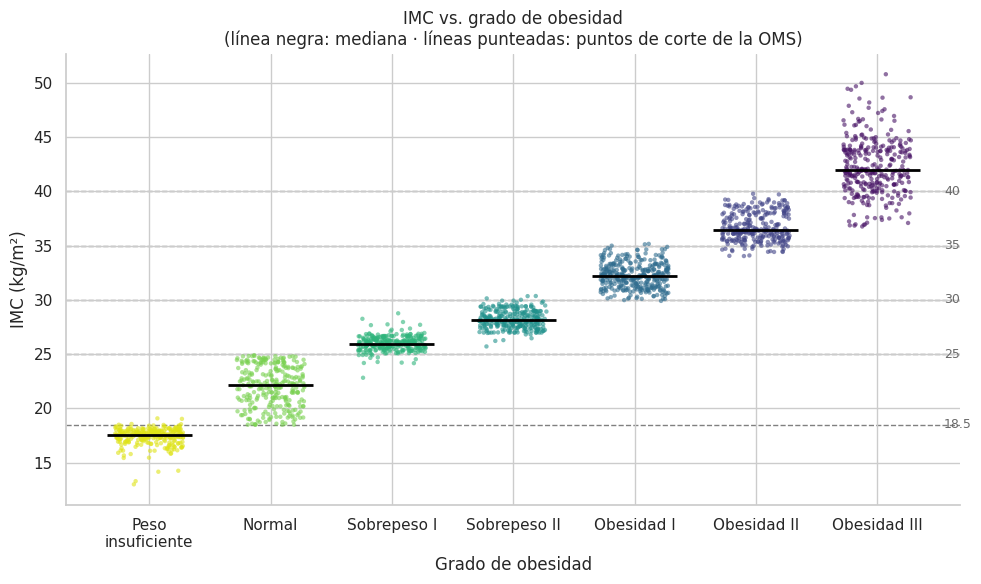

In [8]:
dataset['IMC'] = dataset['Weight'] / dataset['Height']**2

orden = ['Insufficient_Weight', 'Normal_Weight', 'Overweight_Level_I', 'Overweight_Level_II',
         'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III']
etiquetas = ['Peso\ninsuficiente', 'Normal', 'Sobrepeso I', 'Sobrepeso II',
             'Obesidad I', 'Obesidad II', 'Obesidad III']
colores = plt.cm.viridis_r(np.linspace(0.05, 0.95, 7))

fig, ax = plt.subplots(figsize=(10, 6))
rng = np.random.default_rng(0)
for i, (clase, color) in enumerate(zip(orden, colores)):
    imc = dataset.loc[dataset['NObeyesdad'] == clase, 'IMC']
    x = i + rng.uniform(-0.28, 0.28, len(imc))   # dispersión horizontal para que no se encimen
    ax.scatter(x, imc, s=10, color=color, alpha=0.6, edgecolor='none')
    ax.hlines(imc.median(), i - 0.35, i + 0.35, color='black', linewidth=2)   # mediana

# Puntos de corte de la OMS
for v in [18.5, 25, 30, 35, 40]:
    ax.axhline(v, color='gray', linestyle='--', linewidth=1, zorder=0)
    ax.text(6.55, v, f'{v}', va='center', fontsize=9, color='dimgray')

ax.set_xticks(range(7), etiquetas)
ax.set_xlabel('Grado de obesidad')
ax.set_ylabel('IMC (kg/m²)')
ax.set_title('IMC vs. grado de obesidad\n(línea negra: mediana · líneas punteadas: puntos de corte de la OMS)')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

- **Observación**

El IMC aumenta de forma escalonada con cada nivel de obesidad, y casi todos los registros caen dentro de la franja de la OMS que les corresponde (95,2 % de coincidencia). Esto confirma que la variable objetivo se construyó a partir del IMC. Por tanto, si el modelo recibe el peso y la estatura, solo aprendería a recalcular el IMC. Por esta razón se realizó un análisis adicional para evaluar si se debía considerar o no esas características.

### Válidación de balance de clases

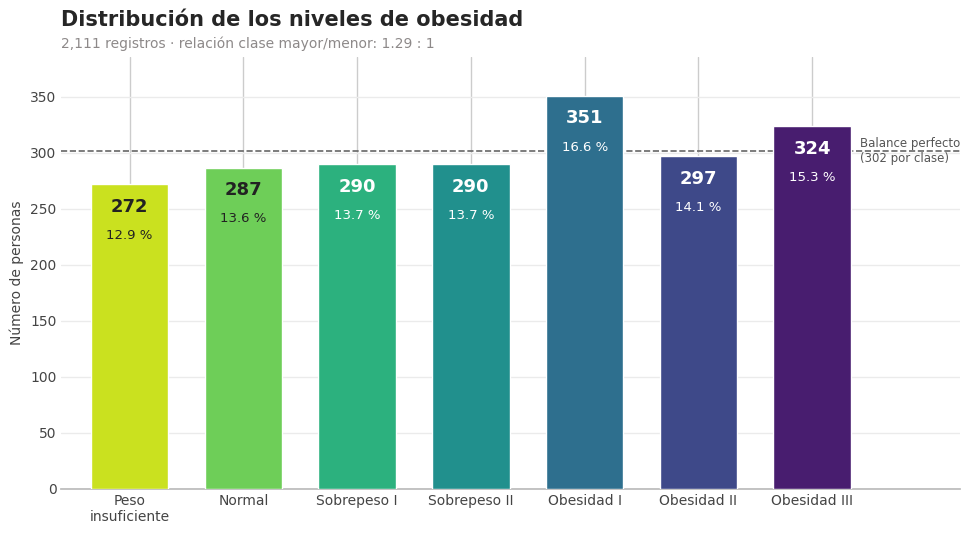

In [9]:
import numpy as np
import matplotlib.pyplot as plt

orden = ['Insufficient_Weight', 'Normal_Weight', 'Overweight_Level_I', 'Overweight_Level_II',
         'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III']
etiquetas = ['Peso\ninsuficiente', 'Normal', 'Sobrepeso I', 'Sobrepeso II',
             'Obesidad I', 'Obesidad II', 'Obesidad III']
conteo = dataset['NObeyesdad'].value_counts().reindex(orden)
porcentaje = conteo / len(dataset) * 100

# Paleta ordenada: de amarillo-verde (peso bajo) a morado (obesidad III)
colores = plt.cm.viridis_r(np.linspace(0.08, 0.92, len(orden)))

fig, ax = plt.subplots(figsize=(10, 5.5))
barras = ax.bar(etiquetas, conteo.values, color=colores, width=0.68, zorder=3)

# Número y porcentaje dentro de cada barra
for barra, n, p, c in zip(barras, conteo.values, porcentaje.values, colores):
    x = barra.get_x() + barra.get_width() / 2
    lum = 0.299*c[0] + 0.587*c[1] + 0.114*c[2]
    texto = '#222222' if lum > 0.55 else 'white'      # texto oscuro en barras claras
    ax.text(x, n - 12, f'{n}', ha='center', va='top', fontsize=13, fontweight='bold', color=texto, zorder=5)
    ax.text(x, n - 40, f'{p:.1f} %', ha='center', va='top', fontsize=9.5, color=texto, zorder=5)

# Línea de balance perfecto (queda detrás de las barras)
ideal = len(dataset) / len(orden)
ax.axhline(ideal, color='#666666', linestyle='--', linewidth=1.2, zorder=2)
ax.text(6.42, ideal, f'Balance perfecto\n({ideal:.0f} por clase)', va='center', fontsize=8.5, color='#555555')

ax.set_title('Distribución de los niveles de obesidad', fontsize=15, fontweight='bold', loc='left', pad=22)
ax.text(0, 1.02, f'{len(dataset):,} registros · relación clase mayor/menor: {conteo.max()/conteo.min():.2f} : 1',
        transform=ax.transAxes, fontsize=10, color="#8D8989")
ax.set_ylabel('Número de personas', fontsize=10, color='#444444')
ax.set_ylim(0, conteo.max() * 1.1)
ax.set_xlim(-0.6, 7.3)
ax.grid(axis='y', color = '#ebebeb', zorder=0)
ax.tick_params(axis='both', length=0, labelsize=10, colors='#444444')
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.spines['bottom'].set_color('#bbbbbb')
plt.tight_layout()
plt.show()

El dataset está balanceado. La clase más grande (Obesidad I) tiene apenas 1,29 veces los registros de la más pequeña (Peso insuficiente). Todas quedan cerca del 14,3 % que tendría un balance perfecto, que es la línea punteada de la gráfica.

### Análisis univariado de las variables númericas

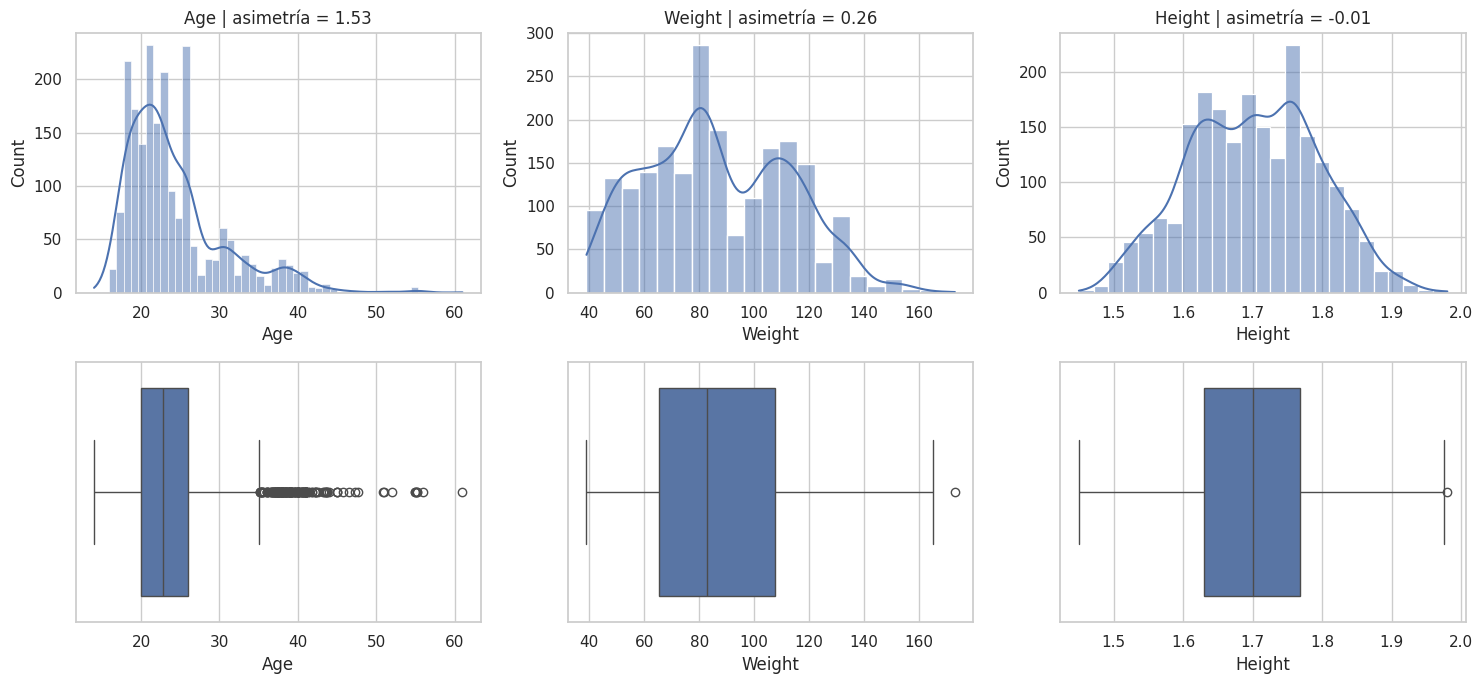

In [10]:
numericas = ["Age", "Weight", "Height"]

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for i, col in enumerate(numericas):
    sns.histplot(dataset[col], kde=True, ax=axes[0, i])
    axes[0, i].set_title(f"{col} | asimetría = {dataset[col].skew():.2f}")
    sns.boxplot(x=dataset[col], ax=axes[1, i])
plt.tight_layout(); plt.show()

#### Observaciones

- *Age* tiene asimetría positiva fuerte (1,53). La mayoría de los encuestados son jóvenes: el 76 % tiene 26 años o menos y la mediana es 22,8. La cola se extiende hasta 61 años. El boxplot marca 168 valores atípicos, todos por encima de unos 35 años. No son errores: son personas mayores que simplemente son pocas en la muestra, así que no hay que eliminarlas. Para el informe, esto significa que los resultados representan sobre todo a población joven.
- *Weight* es casi simétrica (0,26), pero tiene varios picos. Eso tiene sentido, porque mezcla personas de 7 niveles de peso distintos. Solo hay un atípico, de 173 kg, y es un valor plausible.
- *Height* es prácticamente normal (−0,01), con una forma de campana centrada en 1,70 m y sin atípicos relevantes.

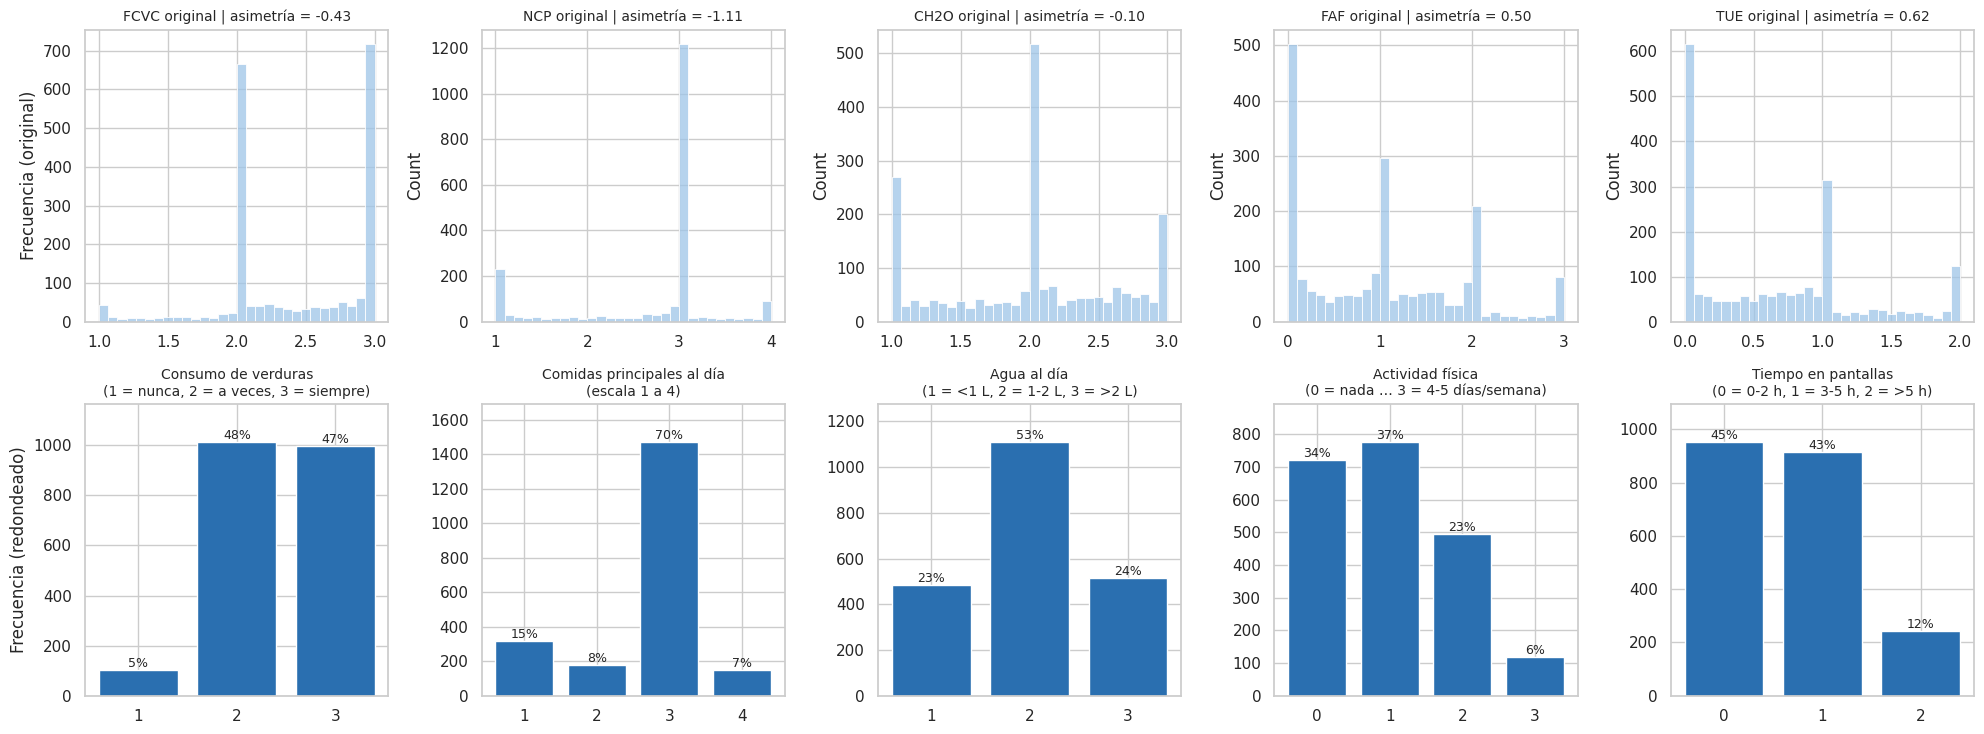

In [11]:
ordinales = {
    "FCVC": "Consumo de verduras\n(1 = nunca, 2 = a veces, 3 = siempre)",
    "NCP":  "Comidas principales al día\n(escala 1 a 4)",
    "CH2O": "Agua al día\n(1 = <1 L, 2 = 1-2 L, 3 = >2 L)",
    "FAF":  "Actividad física\n(0 = nada … 3 = 4-5 días/semana)",
    "TUE":  "Tiempo en pantallas\n(0 = 0-2 h, 1 = 3-5 h, 2 = >5 h)",
}

fig, axes = plt.subplots(2, 5, figsize=(20, 7.5))
for i, (col, titulo) in enumerate(ordinales.items()):
    # Fila 1: valores originales (con decimales sintéticos)
    sns.histplot(dataset[col], bins=30, ax=axes[0, i], color='#9ec5e8')
    axes[0, i].set_title(f"{col} original | asimetría = {dataset[col].skew():.2f}", fontsize=10)
    axes[0, i].set_xlabel('')

    # Fila 2: valores redondeados a la escala de la encuesta
    conteo = dataset[col].round().astype(int).value_counts().sort_index()
    barras = axes[1, i].bar(conteo.index.astype(str), conteo.values, color='#2a6fb0')
    axes[1, i].bar_label(barras, labels=[f'{v/len(dataset):.0%}' for v in conteo.values], fontsize=9)
    axes[1, i].set_title(titulo, fontsize=10)
    axes[1, i].set_ylim(0, conteo.max() * 1.15)

axes[0, 0].set_ylabel('Frecuencia (original)')
axes[1, 0].set_ylabel('Frecuencia (redondeado)')
plt.tight_layout(); plt.show()


#### Observaciones

- *FCVC, verduras*: casi nadie dice “nunca” (5 %). El resto se reparte entre “a veces” (48 %) y “siempre” (47 %).
NCP, comidas al día: la gran mayoría responde 3 (70 %). Es la variable menos variada, así que probablemente aporte poco para distinguir clases.
- *CH2O, agua*: la distribución es la más equilibrada. La mitad toma entre 1 y 2 litros (53 %).
- *FAF, actividad física*: el 34 % no hace nada de ejercicio y solo el 6 % hace 4 o 5 días por semana. Puede ser de las variables más útiles para el modelo.
- *TUE, pantallas*: la mayoría pasa 0–2 h (45 %) o 3–5 h (43 %) frente a pantallas, y solo el 12 % más de 5 h.


### Análisis bivariado

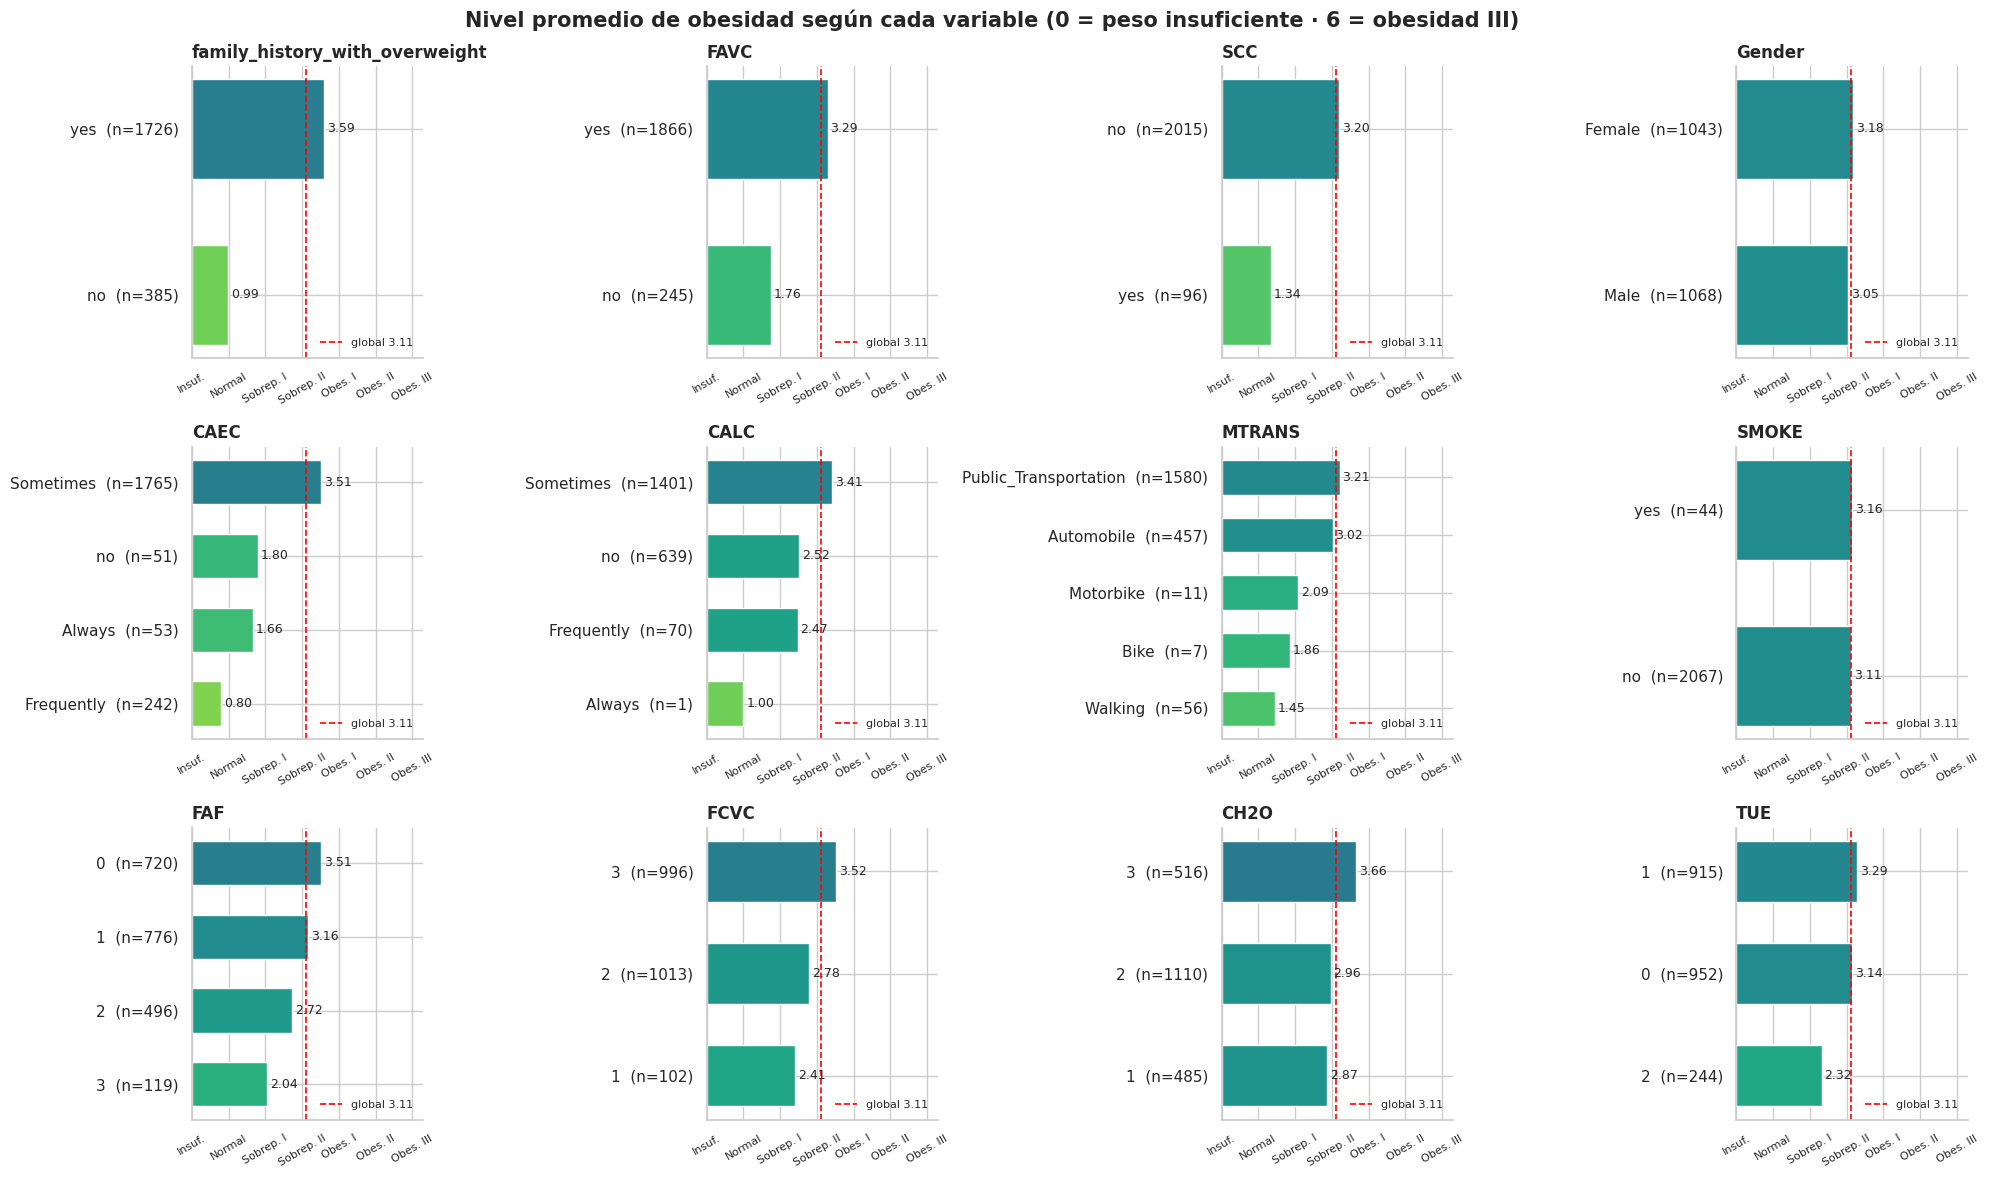

In [12]:
import matplotlib.pyplot as plt

# Codificación ordinal del objetivo: 0 = peso insuficiente ... 6 = obesidad III
niveles = {'Insufficient_Weight': 0, 'Normal_Weight': 1, 'Overweight_Level_I': 2,
           'Overweight_Level_II': 3, 'Obesity_Type_I': 4, 'Obesity_Type_II': 5, 'Obesity_Type_III': 6}
nombres_cortos = ['Insuf.', 'Normal', 'Sobrep. I', 'Sobrep. II', 'Obes. I', 'Obes. II', 'Obes. III']
dataset["nivel"] = dataset["NObeyesdad"].map(niveles)
nivel_global = dataset["nivel"].mean()

dataset_biv = dataset.copy()
for col in ["FCVC", "NCP", "CH2O", "FAF", "TUE"]:
    dataset_biv[col] = dataset_biv[col].round().astype(int)

variables = ["family_history_with_overweight", "FAVC", "SCC", "Gender",
             "CAEC", "CALC", "MTRANS", "SMOKE",
             "FAF", "FCVC", "CH2O", "TUE"]
cmap = plt.cm.viridis_r

fig, axes = plt.subplots(3, 4, figsize=(20, 12))
for ax, col in zip(axes.ravel(), variables):
    grupo = dataset_biv.groupby(col)["nivel"].agg(["mean", "size"]).sort_values("mean")
    etiquetas = [f"{c}  (n={n})" for c, n in zip(grupo.index.astype(str), grupo["size"])]
    colores = cmap(0.08 + 0.84 * grupo["mean"].values / 6)   # el color refleja el nivel promedio
    ax.barh(etiquetas, grupo["mean"].values, color=colores, height=0.6)
    for y, v in enumerate(grupo["mean"].values):
        ax.text(v + 0.08, y, f"{v:.2f}", va="center", fontsize=9)
    ax.axvline(nivel_global, color="red", ls="--", lw=1.2, label=f"global {nivel_global:.2f}")
    ax.set_xlim(0, 6.3)
    ax.set_xticks(range(7), nombres_cortos, fontsize=8, rotation=30)
    ax.set_title(col, fontsize=12, fontweight="bold", loc="left")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="lower right", fontsize=8, frameon=False)

fig.suptitle("Nivel promedio de obesidad según cada variable (0 = peso insuficiente · 6 = obesidad III)",
             fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

- **Observaciones**

La línea roja marca el nivel promedio global (3,11, cercano a Sobrepeso II). Las barras que la superan corresponden a grupos con más obesidad que el promedio, y las que no la alcanzan, a grupos con menos.

- *Antecedentes familiares*: es la variable con mayor diferencia. Quienes no tienen antecedentes promedian 0,99 (peso normal), mientras que quienes sí los tienen llegan a 3,59 (entre sobrepeso II y obesidad I).
- *Hábitos de control*: quienes controlan las calorías que consumen (`SCC`) promedian 1,34 frente a 3,20 de quienes no lo hacen. Algo similar ocurre con el consumo frecuente de comida calórica (`FAVC`): 1,76 sin el hábito y 3,29 con él.
- *Actividad física (`FAF`)*: muestra el patrón más coherente. El nivel baja a medida que aumenta el ejercicio, de 3,51 en quienes no hacen nada a 2,04 en quienes se ejercitan 4–5 días por semana.
- *Transporte (`MTRANS`)*: quienes caminan promedian 1,45, muy por debajo de quienes usan transporte público (3,21) o automóvil (3,02).
- *Relaciones contraintuitivas*: quienes comen verduras "siempre" (`FCVC`) o toman más de 2 L de agua (`CH2O`) tienen mayor nivel de obesidad (3,52 y 3,66), y quienes comen entre comidas "frecuentemente" (`CAEC`) tienen el nivel más bajo (0,80). Esto puede deberse a causalidad inversa (personas con obesidad que cambiaron sus hábitos por recomendación médica) o a artefactos del sobremuestreo sintético.
- *Género*: hombres (3,05) y mujeres (3,18) parecen iguales, pero el promedio esconde una diferencia importante: Obesidad II está compuesta casi solo por hombres y Obesidad III casi solo por mujeres. Esto se confirma con la V de Cramér.
- *Sin diferencia*: fumar (`SMOKE`) y el tiempo frente a pantallas (`TUE`) no muestran diferencias relevantes respecto al promedio.

Fianlmente, se puede notar que también hay categorías con muy pocos registros (`CALC = Always` con n = 1, `Bike` con n = 7 y `Motorbike` con n = 11) no permiten sacar conclusiones confiables.

### V de Cramer

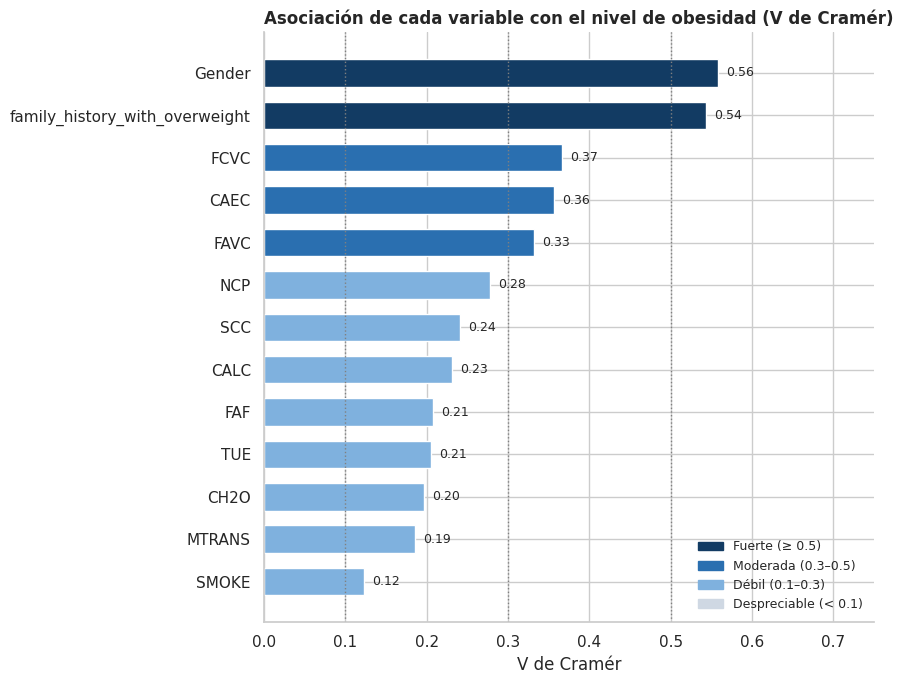

In [13]:
def v_cramer(x, y):
    tabla = pd.crosstab(x, y)
    chi2, p = chi2_contingency(tabla, correction=False)[:2]
    n = tabla.values.sum()
    r, k = tabla.shape
    return np.sqrt((chi2 / n) / (min(r, k) - 1)), p

# Ordinales numéricas redondeadas a su escala
dataset_cat = dataset.copy()
for col in ["FCVC", "NCP", "CH2O", "FAF", "TUE"]:
    dataset_cat[col] = dataset_cat[col].round().astype(int)

cat_vars = [c for c in dataset_cat.select_dtypes(include=["object", "string"]).columns if c != "NObeyesdad"] \
           + ["FCVC", "NCP", "CH2O", "FAF", "TUE"]

resultados = pd.DataFrame(
    [v_cramer(dataset_cat[c], dataset_cat["NObeyesdad"]) for c in cat_vars],
    index=cat_vars, columns=["V de Cramér", "p-valor"]
).sort_values("V de Cramér")

# Gráfica coloreada por fuerza de asociación
def fuerza(v):
    return "Fuerte" if v >= 0.5 else "Moderada" if v >= 0.3 else "Débil" if v >= 0.1 else "Despreciable"
colores_fuerza = {"Fuerte": "#123b63", "Moderada": "#2a6fb0", "Débil": "#7fb1de", "Despreciable": "#cfd8e3"}
colores = [colores_fuerza[fuerza(v)] for v in resultados["V de Cramér"]]

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(resultados.index, resultados["V de Cramér"], color=colores, height=0.65)
for y, v in enumerate(resultados["V de Cramér"]):
    ax.text(v + 0.01, y, f"{v:.2f}", va="center", fontsize=9)
for umbral in [0.1, 0.3, 0.5]:
    ax.axvline(umbral, color="gray", ls=":", lw=1)
ax.set_xlim(0, 0.75)
ax.set_xlabel("V de Cramér")
ax.set_title("Asociación de cada variable con el nivel de obesidad (V de Cramér)", loc="left", fontweight="bold")
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in colores_fuerza.values()],
          ["Fuerte (≥ 0.5)", "Moderada (0.3–0.5)", "Débil (0.1–0.3)", "Despreciable (< 0.1)"],
          loc="lower right", frameon=False, fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

In [14]:
# Género por clase: evidencia del sesgo (Obesity_II casi solo hombres, Obesity_III casi solo mujeres)
orden_clases = ["Insufficient_Weight", "Normal_Weight", "Overweight_Level_I", "Overweight_Level_II",
                "Obesity_Type_I", "Obesity_Type_II", "Obesity_Type_III"]
pd.crosstab(dataset["NObeyesdad"], dataset["Gender"]).reindex(orden_clases)

Gender,Female,Male
NObeyesdad,,
Insufficient_Weight,173,99
Normal_Weight,141,146
Overweight_Level_I,145,145
Overweight_Level_II,103,187
Obesity_Type_I,156,195
Obesity_Type_II,2,295
Obesity_Type_III,323,1


- **Observaciones**

Todas las asociaciones son estadísticamente significativas (p ≈ 0), así que lo que importa es su fuerza.

- *Antecedentes familiares* (0,54): es la variable fuerte con sentido real. Casi todas las personas con obesidad tipo I, II y III tienen familiares con sobrepeso.
- *FCVC*, *CAEC* y *FAVC* (0,33 a 0,37): asociación moderada (verduras, comida entre comidas y comida hipercalórica).
- *NCP*, *CALC*, *FAF*, *TUE*, *CH2O*, *MTRANS* y *SMOKE*: asociación débil. Individualmente aportan poco, pero pueden sumar en conjunto.
- ***Gender* (0,56) sale como la variable más fuerte, pero es un sesgo del dataset y no un hallazgo.** Obesidad II tiene 295 hombres y 2 mujeres; Obesidad III tiene 323 mujeres y 1 hombre. Esas clases tienen muy pocas personas reales (unas 11 y 3) y casi todas son sintéticas, generadas con SMOTE a partir de ellas, así que heredaron un género casi puro. En las filas reales el género se reparte parejo en todas las clases.

**Decisión pendiente:** hay que definir qué hacer con *Gender* en el modelo. Las opciones son (1) dejarlo, asumiendo el sesgo y dejándolo documentado; (2) quitarlo del benchmark preventivo; o (3) probar el modelo con y sin *Gender* (y comparar, idealmente también sobre las filas reales) para ver cuánto cambia el rendimiento y la interpretación con SHAP. Por ahora se mantiene en el preventivo, y el riesgo es que el modelo aprenda el atajo "hombre = Obesidad II, mujer = Obesidad III", que infle las métricas y que SHAP muestre el género como un factor de peso que no lo es.

### Codificación de variables categóricas de entrada

In [15]:
data = dataset.copy()

# Binarias
data["Gender"] = data["Gender"].map({"Female": 0, "Male": 1})
for col in ["family_history_with_overweight", "FAVC", "SMOKE", "SCC"]:
    data[col] = data[col].map({"no": 0, "yes": 1})

# Ordinales
for col in ["FCVC", "NCP", "CH2O", "FAF", "TUE"]:
    data[col] = data[col].round().astype(int)

orden_frecuencia = {"no": 0, "Sometimes": 1, "Frequently": 2, "Always": 3}
data["CAEC"] = data["CAEC"].map(orden_frecuencia)
data["CALC"] = data["CALC"].replace("Always", "Frequently")   # "Always" tiene 1 solo registro
data["CALC"] = data["CALC"].map(orden_frecuencia)

# Nominales
data["MTRANS"] = data["MTRANS"].replace({"Bike": "Two_Wheels", "Motorbike": "Two_Wheels"})  # 7 y 11 casos
data = pd.get_dummies(data, columns=["MTRANS"], prefix="MTRANS", dtype=int)

# Target: codificación ordinal de 0 a 6 (peso insuficiente … obesidad III)
niveles = {
    "Insufficient_Weight": 0,
    "Normal_Weight": 1,
    "Overweight_Level_I": 2,
    "Overweight_Level_II": 3,
    "Obesity_Type_I": 4,
    "Obesity_Type_II": 5,
    "Obesity_Type_III": 6,
}
data["NObeyesdad"] = data["NObeyesdad"].map(niveles)
nombres_clases = {v: k for k, v in niveles.items()}   # para volver a nombres al mostrar resultados

# Verificación de la transformación
print(f"Dimensiones: {data.shape}")
print(f"Nulos totales: {data.isna().sum().sum()}")
print(f"Columnas no numéricas: {data.select_dtypes(exclude='number').columns.tolist()}")
print("\nValores únicos por columna (excepto continuas):")
for col in data.columns.drop(["Age", "Height", "Weight"]):
    print(f"  {col:32s} {sorted(data[col].unique().tolist())}")

data.head()

Dimensiones: (2111, 22)
Nulos totales: 0
Columnas no numéricas: []

Valores únicos por columna (excepto continuas):
  Gender                           [0, 1]
  family_history_with_overweight   [0, 1]
  FAVC                             [0, 1]
  FCVC                             [1, 2, 3]
  NCP                              [1, 2, 3, 4]
  CAEC                             [0, 1, 2, 3]
  SMOKE                            [0, 1]
  CH2O                             [1, 2, 3]
  SCC                              [0, 1]
  FAF                              [0, 1, 2, 3]
  TUE                              [0, 1, 2]
  CALC                             [0, 1, 2]
  NObeyesdad                       [0, 1, 2, 3, 4, 5, 6]
  IMC                              [12.998684889724604, 13.291587901701323, 14.160574669617416, 14.25387559306874, 15.432098765432098, 15.457234117286061, 15.665158448270383, 15.792641075006339, 15.822158933586486, 15.8592959374506, 15.905787660342869, 16.027529774529064, 16.088735295769812, 

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,NObeyesdad,IMC,nivel,MTRANS_Automobile,MTRANS_Public_Transportation,MTRANS_Two_Wheels,MTRANS_Walking
0,0,21.000,1.620,64.000,1,0,2,3,1,0,2,0,0,1,0,1,24.387,1,0,1,0,0
1,0,21.000,1.520,56.000,1,0,3,3,1,1,3,1,3,0,1,1,24.238,1,0,1,0,0
2,1,23.000,1.800,77.000,1,0,2,3,1,0,2,0,2,1,2,1,23.765,1,0,1,0,0
3,1,27.000,1.800,87.000,0,0,3,3,1,0,2,0,2,0,2,2,26.852,2,0,0,0,1
4,1,22.000,1.780,89.800,0,0,2,1,1,0,2,0,0,0,1,3,28.342,3,0,1,0,0


- **Observaciones**

Las variables binarias se codificaron como 0/1; las ordinales, respetando su orden; MTRANS con one-hot, agrupando bicicleta y moto por tener pocos casos; y el objetivo de 0 a 6. Las ordinales numéricas se redondearon a la escala original de la encuesta. La codificación se aplica antes de la división porque usa mapeos fijos que no dependen de los datos, por lo que no introduce fuga de información.

### Matriz de Spearman para Variables Numéricas

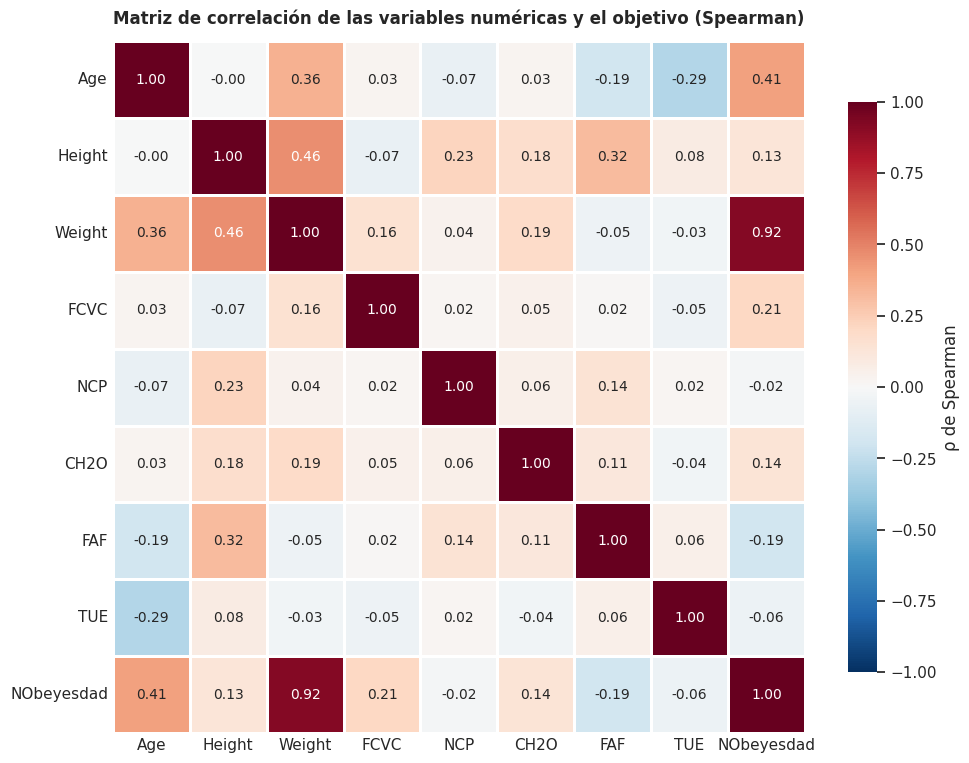

In [16]:
numericas = ["Age", "Height", "Weight", "FCVC", "NCP", "CH2O", "FAF", "TUE", "NObeyesdad"]
corr = data[numericas].corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            square=True, linewidths=1, linecolor="white", annot_kws={"size": 10},
            cbar_kws={"shrink": 0.8, "label": "ρ de Spearman"}, ax=ax)

ax.set_title("Matriz de correlación de las variables numéricas y el objetivo (Spearman)",
             loc="left", fontweight="bold", fontsize=12, pad=12)
ax.tick_params(length=0)
plt.xticks(rotation=0); plt.yticks(rotation=0)
plt.tight_layout(); plt.show()

### División del Dataset Train / Test

Se eliminan los duplicados y se dividen los datos 80/20 estratificado. Se arman dos conjuntos de variables con las mismas filas:

- **Preventivo (principal):** hábitos, antecedentes, edad y género. Sin peso, estatura ni IMC (fuga de información). *Gender* se mantiene por ahora, pero presenta un sesgo del dataset sintético (ver observaciones de la V de Cramér) y su uso está por decidir.
- **Operativo (referencia):** todas las variables más IMC, para medir el efecto de la fuga.

In [17]:
# Duplicados: se eliminan ANTES de dividir, para que una misma persona no quede en entrenamiento y en prueba
sin_dup = ~dataset.duplicated()
print(f"Duplicados eliminados: {(~sin_dup).sum()} ({len(dataset)} -> {sin_dup.sum()} registros)")
data_u = data[sin_dup]

# Nunca son variables de entrada: el target y 'nivel' (copia numérica del target, creada para graficar)
excluir = ["NObeyesdad", "nivel"]

# Benchmark preventivo (principal): hábitos, antecedentes, edad y género. Sin Weight, Height ni IMC (fuga: la clase se calcula con ellos)
# OJO: Gender tiene sesgo por el SMOTE (Obesity_II casi todo hombres, Obesity_III casi todo mujeres). Se mantiene por ahora; decisión pendiente
X_prev = data_u.drop(columns=excluir + ["Weight", "Height", "IMC"])
# Benchmark operativo (referencia): todas las variables + IMC, para medir el efecto de la fuga
X_oper = data_u.drop(columns=excluir)
y = data_u["NObeyesdad"]

# Un único split para ambos benchmarks (mismas filas, misma semilla)
idx_train, idx_test = train_test_split(
    y.index, test_size=0.2, stratify=y, random_state=SEMILLA)

X_train, X_test = X_prev.loc[idx_train], X_prev.loc[idx_test]               # preventivo
X_train_oper, X_test_oper = X_oper.loc[idx_train], X_oper.loc[idx_test]     # operativo
y_train, y_test = y.loc[idx_train], y.loc[idx_test]

# Verificación anti-fuga
assert not {"NObeyesdad", "nivel", "Weight", "Height", "IMC"} & set(X_train.columns), "Fuga en el preventivo"
assert not {"NObeyesdad", "nivel"} & set(X_train_oper.columns), "El target está en las variables de entrada"

print("\nPreventivo -> Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print("Operativo  -> Entrenamiento:", X_train_oper.shape, "| Prueba:", X_test_oper.shape)

# Proporción de cada clase en total, entrenamiento y prueba
proporciones = pd.DataFrame({
    "Total (%)": y.value_counts(normalize=True),
    "Entrenamiento (%)": y_train.value_counts(normalize=True),
    "Prueba (%)": y_test.value_counts(normalize=True),
}).sort_index()
proporciones.index = proporciones.index.map(nombres_clases)
print((proporciones * 100).round(1))

Duplicados eliminados: 24 (2111 -> 2087 registros)

Preventivo -> Entrenamiento: (1669, 17) | Prueba: (418, 17)
Operativo  -> Entrenamiento: (1669, 20) | Prueba: (418, 20)
                     Total (%)  Entrenamiento (%)  Prueba (%)
NObeyesdad                                                   
Insufficient_Weight     12.800             12.800      12.700
Normal_Weight           13.500             13.500      13.600
Overweight_Level_I      13.200             13.200      13.200
Overweight_Level_II     13.900             13.900      13.900
Obesity_Type_I          16.800             16.800      16.700
Obesity_Type_II         14.200             14.200      14.400
Obesity_Type_III        15.500             15.500      15.600


---
# Paso 3 · Metodologías de Preprocesamiento (`P1`, `P2` y `P3`)

Cada metodología se define directamente en este cuaderno y se encapsula en un `Pipeline` de `scikit-learn` para que sus parámetros se calculen **solo con entrenamiento** (cero fuga de datos):

- **P1 · Escalado Robusto (`RobustScaler`):** 17 variables base centradas con mediana y escaladas por IQR (resistente a valores atípicos como `Age`).
- **P2 · Ingeniería de Hábitos + Yeo-Johnson + `StandardScaler`:** agrega 4 variables conductuales sin peso ni estatura (21 en total) y corrige la asimetría.
- **P3 · `RobustScaler` + `PCA 95 %`:** comprime las 17 variables en componentes ortogonales reteniendo al menos el 95 % de la varianza.

Diagnóstico P1 (RobustScaler en entrenamiento):


,Mediana antes,IQR antes,Mediana P1,IQR P1
Age,22.883,6.052,0.000,1.000
FCVC,2.000,1.000,0.000,1.000
NCP,3.000,0.000,0.000,0.000
CH2O,2.000,0.000,0.000,0.000
FAF,1.000,2.000,0.000,1.000
TUE,1.000,1.000,0.000,1.000
CAEC,1.000,0.000,0.000,0.000
CALC,1.000,1.000,0.000,1.000


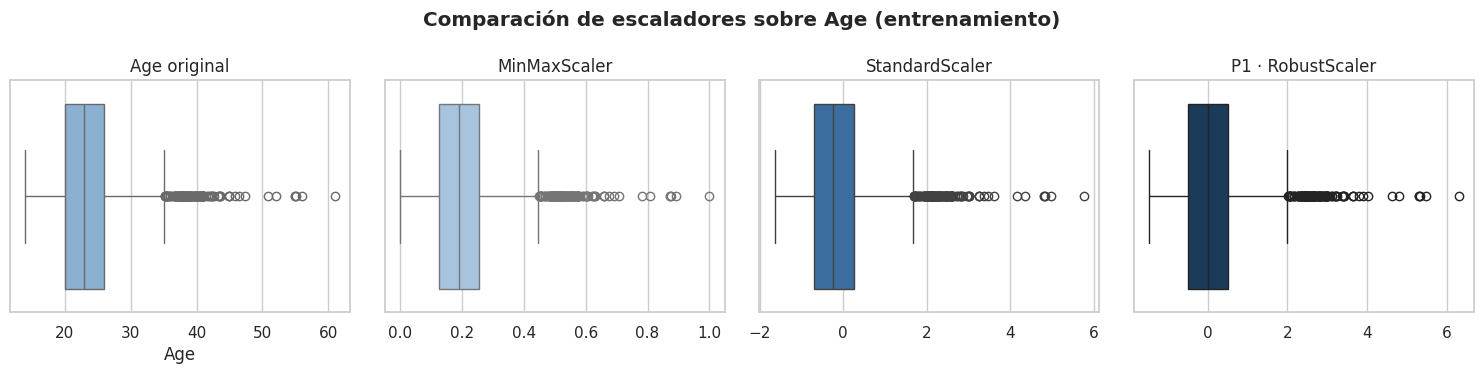

In [18]:
# --- P1: Escalado Robusto (solo sobre entrenamiento para el diagnóstico) ---
escalador_p1 = RobustScaler()
X_train_p1 = pd.DataFrame(
    escalador_p1.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index,
)

cols_escala = ["Age", "FCVC", "NCP", "CH2O", "FAF", "TUE", "CAEC", "CALC"]
resumen_p1 = pd.DataFrame({
    "Mediana antes": X_train[cols_escala].median(),
    "IQR antes": X_train[cols_escala].quantile(0.75) - X_train[cols_escala].quantile(0.25),
    "Mediana P1": X_train_p1[cols_escala].median().round(3),
    "IQR P1": (X_train_p1[cols_escala].quantile(0.75) - X_train_p1[cols_escala].quantile(0.25)).round(3),
})
print("Diagnóstico P1 (RobustScaler en entrenamiento):")
display(resumen_p1)

# Comparar cómo escalan la variable Age los 3 escaladores vistos en clase
age_df = X_train[["Age"]]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))

sns.boxplot(x=age_df["Age"], ax=axes[0], color="#7fb1de")
axes[0].set_title("Age original")

sns.boxplot(x=MinMaxScaler().fit_transform(age_df).ravel(), ax=axes[1], color="#9ec5e8")
axes[1].set_title("MinMaxScaler")

sns.boxplot(x=StandardScaler().fit_transform(age_df).ravel(), ax=axes[2], color="#2a6fb0")
axes[2].set_title("StandardScaler")

sns.boxplot(x=RobustScaler().fit_transform(age_df).ravel(), ax=axes[3], color="#123b63")
axes[3].set_title("P1 · RobustScaler")

plt.suptitle("Comparación de escaladores sobre Age (entrenamiento)", fontweight="bold")
plt.tight_layout()
plt.show()

P2 -> columnas entrada: 17 | columnas salida: 21


,Asimetría antes,Asimetría después
Age,1.466,0.087
FCVC,-0.435,-0.169
NCP,-1.085,-0.091
CAEC,2.057,-0.156
CH2O,-0.035,-0.065
FAF,0.452,-0.033
TUE,0.519,0.051
CALC,-0.248,-0.108
Balance_Act_Sed,1.041,0.071
Hidratacion_Activa,1.005,0.005


,Spearman rho,p-valor
Variable,,
Balance_Act_Sed,-0.162,0.000
Hidratacion_Activa,-0.056,0.023
Riesgo_Gen_Cal,0.520,0.000
Indice_Protector,-0.025,0.313


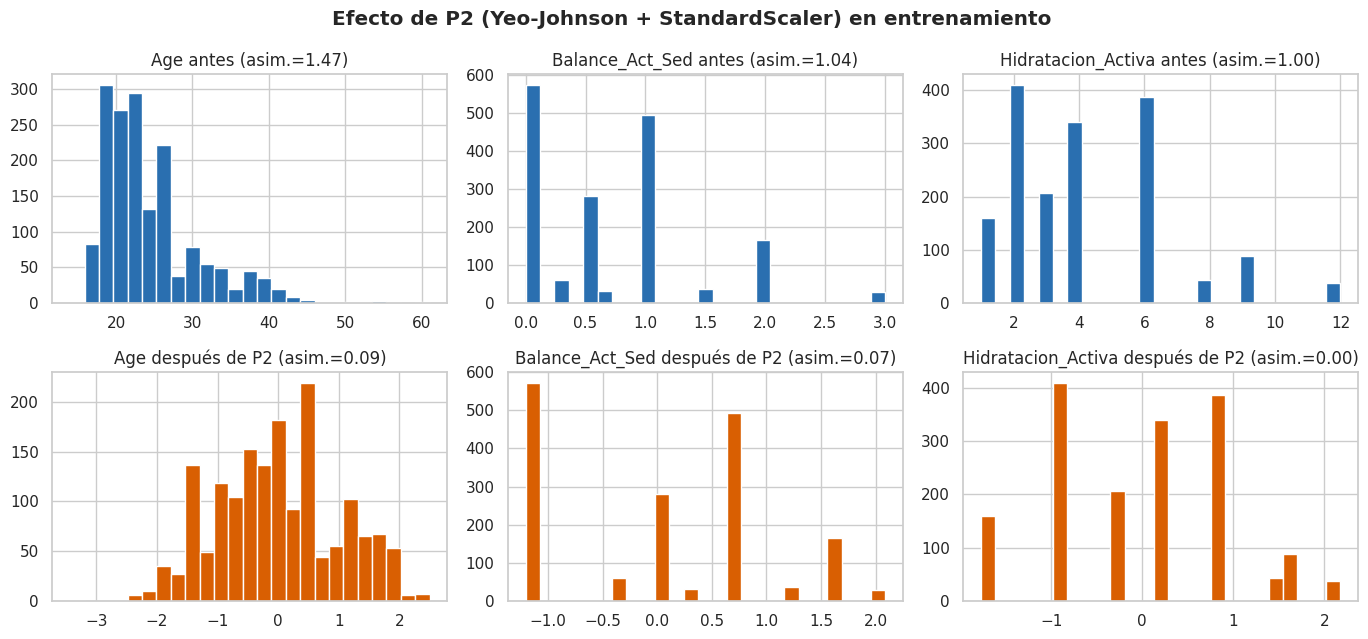

In [19]:
# --- P2: Ingeniería de Hábitos + Yeo-Johnson + StandardScaler (definido en el cuaderno) ---
HABIT_FEATURES = ["Balance_Act_Sed", "Hidratacion_Activa", "Riesgo_Gen_Cal", "Indice_Protector"]
FORBIDDEN_COLUMNS = ["Weight", "Height", "IMC"]


def agregar_habitos(X):
    """Agrega 4 variables de hábitos sin usar peso, estatura ni IMC."""
    presentes = [c for c in FORBIDDEN_COLUMNS if c in X.columns]
    if presentes:
        raise ValueError(f"P2 no admite variables antropométricas (fuga de IMC): {presentes}")

    X = X.copy()
    X["Balance_Act_Sed"] = X["FAF"] / (X["TUE"] + 1)
    X["Hidratacion_Activa"] = X["CH2O"] * (X["FAF"] + 1)
    X["Riesgo_Gen_Cal"] = X["family_history_with_overweight"] * X["FAVC"]
    X["Indice_Protector"] = X["FCVC"] + X["CH2O"] + X["FAF"] + X["SCC"] - X["FAVC"]
    return X


def nombres_con_habitos(transformer, input_features):
    return list(input_features) + HABIT_FEATURES


def columnas_continuas(X):
    return [c for c in X.columns if X[c].nunique() > 2]


def construir_p2(X_ejemplo):
    """Devuelve el Pipeline P2 sin ajustar (Yeo-Johnson en continuas + StandardScaler en binarias)."""
    continuas = columnas_continuas(agregar_habitos(X_ejemplo))
    transformacion = ColumnTransformer(
        [("yeo_johnson", PowerTransformer(method="yeo-johnson", standardize=True), continuas)],
        remainder=StandardScaler(),
        verbose_feature_names_out=False,
    )
    return Pipeline([
        ("habitos", FunctionTransformer(agregar_habitos, feature_names_out=nombres_con_habitos)),
        ("transformacion", transformacion),
    ])


# Probar P2 solo sobre entrenamiento
p2_demo = construir_p2(X_train).set_output(transform="pandas")
X_train_p2 = p2_demo.fit_transform(X_train)

# Verificar que ninguna variable con fuga (Weight, Height, IMC) esté presente
assert not set(FORBIDDEN_COLUMNS) & set(X_train_p2.columns), "Hay variables prohibidas en P2"
print("P2 -> columnas entrada:", X_train.shape[1], "| columnas salida:", X_train_p2.shape[1])

# Revisar reducción de asimetría antes y después de Yeo-Johnson
crudo_p2 = agregar_habitos(X_train)
cols_cont = columnas_continuas(crudo_p2)

tabla_asimetria = pd.DataFrame({
    "Asimetría antes": [skew(crudo_p2[c]) for c in cols_cont],
    "Asimetría después": [skew(X_train_p2[c]) for c in cols_cont],
}, index=cols_cont)
display(tabla_asimetria.round(3))

# Correlación de Spearman de las 4 variables nuevas con la clase
corrs_p2 = []
for col in HABIT_FEATURES:
    rho, pval = spearmanr(crudo_p2[col], y_train)
    corrs_p2.append({"Variable": col, "Spearman rho": rho, "p-valor": pval})
display(pd.DataFrame(corrs_p2).set_index("Variable").round(4))

# Gráfica antes y después en 3 variables representativas
vars_ejemplo = ["Age", "Balance_Act_Sed", "Hidratacion_Activa"]
fig, axes = plt.subplots(2, 3, figsize=(14, 6.5))
for j, col in enumerate(vars_ejemplo):
    axes[0, j].hist(crudo_p2[col], bins=25, color="#2a6fb0", edgecolor="white")
    axes[0, j].set_title(f"{col} antes (asim.={skew(crudo_p2[col]):.2f})")
    axes[1, j].hist(X_train_p2[col], bins=25, color="#d95f02", edgecolor="white")
    axes[1, j].set_title(f"{col} después de P2 (asim.={skew(X_train_p2[col]):.2f})")

plt.suptitle("Efecto de P2 (Yeo-Johnson + StandardScaler) en entrenamiento", fontweight="bold")
plt.tight_layout()
plt.show()

P3 -> entrada: 17 variables | salida: 11 componentes | varianza retenida: 95.76 %
Correlación máxima entre componentes PCA (debe ser ~0): 1.47e-15


,Componente,Varianza (%),Acumulada (%)
0,PC1,28.570,28.570
1,PC2,14.170,42.740
2,PC3,10.640,53.370
3,PC4,9.250,62.620
4,PC5,7.870,70.490
5,PC6,5.970,76.450
6,PC7,5.070,81.530
7,PC8,4.820,86.340
8,PC9,3.700,90.040
9,PC10,3.200,93.250


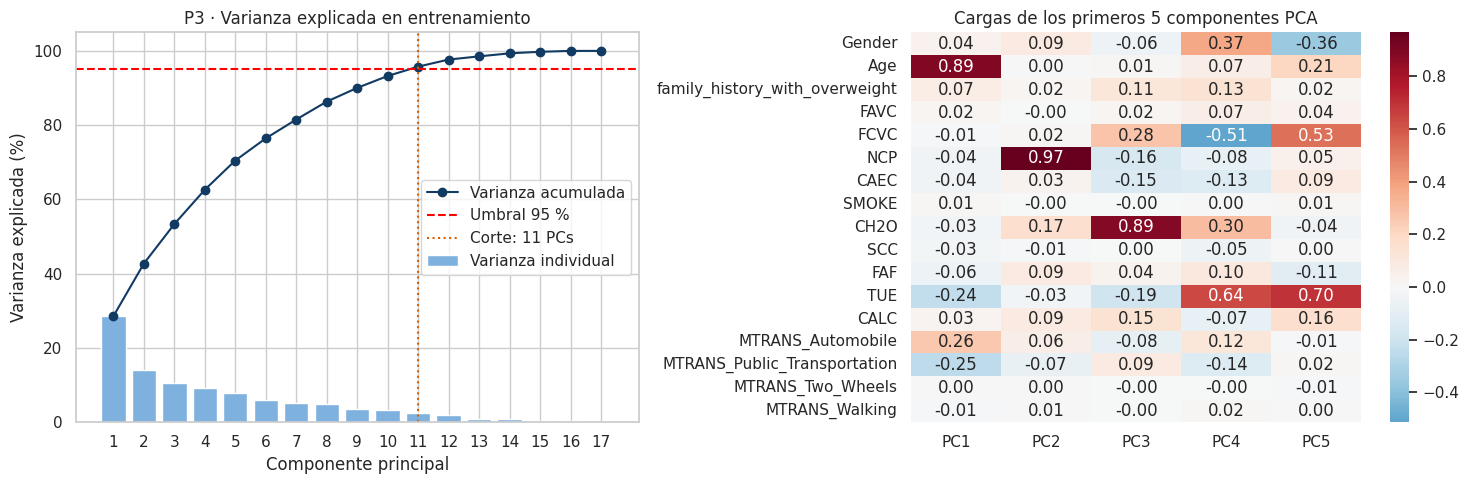

In [20]:
# --- P3: Escalado Robusto + PCA reteniendo 95 % de varianza ---
p3_demo = Pipeline([
    ("scaler", RobustScaler()),
    ("pca", PCA(n_components=0.95, random_state=SEMILLA)),
])
X_train_p3 = p3_demo.fit_transform(X_train)
pca_95 = p3_demo.named_steps["pca"]

k_pca = pca_95.n_components_
var_total = pca_95.explained_variance_ratio_.sum() * 100
print(f"P3 -> entrada: {X_train.shape[1]} variables | salida: {k_pca} componentes | varianza retenida: {var_total:.2f} %")

# Verificar ortogonalidad entre los componentes obtenidos
corr_max_pca = np.abs(np.corrcoef(X_train_p3.T) - np.eye(k_pca)).max()
print(f"Correlación máxima entre componentes PCA (debe ser ~0): {corr_max_pca:.2e}")

# PCA completo solo para dibujar la curva de varianza acumulada
pca_completo = PCA(random_state=SEMILLA).fit(X_train_p1)
var_ind = pca_completo.explained_variance_ratio_ * 100
var_acum = np.cumsum(var_ind)

tabla_pca = pd.DataFrame({
    "Componente": [f"PC{i}" for i in range(1, k_pca + 1)],
    "Varianza (%)": (pca_95.explained_variance_ratio_ * 100).round(2),
    "Acumulada (%)": (np.cumsum(pca_95.explained_variance_ratio_) * 100).round(2),
})
display(tabla_pca)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Gráfica 1: Varianza individual y acumulada
ejes = list(range(1, len(var_ind) + 1))
axes[0].bar(ejes, var_ind, color="#7fb1de", label="Varianza individual")
axes[0].plot(ejes, var_acum, marker="o", color="#123b63", label="Varianza acumulada")
axes[0].axhline(95, color="red", ls="--", label="Umbral 95 %")
axes[0].axvline(k_pca, color="#d95f02", ls=":", label=f"Corte: {k_pca} PCs")
axes[0].set_xticks(ejes)
axes[0].set_xlabel("Componente principal")
axes[0].set_ylabel("Varianza explicada (%)")
axes[0].set_title("P3 · Varianza explicada en entrenamiento")
axes[0].legend()

# Gráfica 2: Pesos (loadings) de los primeros 5 componentes
cargas = pd.DataFrame(
    pca_95.components_[:5].T,
    index=X_train.columns,
    columns=["PC1", "PC2", "PC3", "PC4", "PC5"],
)
sns.heatmap(cargas, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[1])
axes[1].set_title("Cargas de los primeros 5 componentes PCA")

plt.tight_layout()
plt.show()

---
# Paso 4 · Protocolo de Entrenamiento y Medición de Complejidad

Todos los modelos se entrenan bajo el mismo protocolo para que la comparación sea justa:
- Validación cruzada estratificada de **5 particiones** (`StratifiedKFold`, `SEMILLA = 20`).
- Búsqueda aleatoria de hiperparámetros (`RandomizedSearchCV`, `n_iter = 30`, métrica `f1_macro`).
- Medición empírica de **tiempo de entrenamiento (s)**, **latencia de inferencia (ms/muestra)** y **tamaño del archivo `.pkl` (KB)**.

In [21]:
cv_5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

etiquetas_clases = [
    "Peso insuf.", "Normal", "Sobrepeso I", "Sobrepeso II",
    "Obesidad I", "Obesidad II", "Obesidad III",
]


def evaluar_modelo(nombre_modelo, nombre_prep, pipeline, param_grid, X_tr, y_tr, X_te, y_te, benchmark="Preventivo"):
    """Ajusta un pipeline con RandomizedSearchCV (5-Fold) y devuelve el modelo y sus métricas."""
    t_busqueda = time.time()

    busqueda = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_grid,
        n_iter=30,
        scoring="f1_macro",
        cv=cv_5,
        random_state=SEMILLA,
        n_jobs=-1,
        return_train_score=True,
    )
    busqueda.fit(X_tr, y_tr)

    # Reentrenar el mejor pipeline limpio para medir el tiempo exacto de fit
    mejor_modelo = clone(busqueda.best_estimator_)
    if "clf__n_jobs" in mejor_modelo.get_params():
        mejor_modelo.set_params(clf__n_jobs=-1)

    t0 = time.perf_counter()
    mejor_modelo.fit(X_tr, y_tr)
    tiempo_fit = time.perf_counter() - t0

    # Medir tiempo de predicción en prueba
    t0 = time.perf_counter()
    y_pred_test = mejor_modelo.predict(X_te)
    latencia_ms = (time.perf_counter() - t0) * 1000
    y_pred_train = mejor_modelo.predict(X_tr)

    # Medir tamaño del archivo .pkl en KB
    ruta_tmp = os.path.join(CARPETA_MODELOS, "_tmp_medicion.pkl")
    joblib.dump(mejor_modelo, ruta_tmp)
    tamano_kb = os.path.getsize(ruta_tmp) / 1024
    os.remove(ruta_tmp)

    # Extraer F1-macro de los 5 pliegues del mejor candidato
    idx = busqueda.best_index_
    cv_scores = [busqueda.cv_results_[f"split{k}_test_score"][idx] for k in range(5)]
    cv_media = float(np.mean(cv_scores))
    cv_std = float(np.std(cv_scores))

    train_acc = accuracy_score(y_tr, y_pred_train)
    test_acc = accuracy_score(y_te, y_pred_test)
    test_f1 = f1_score(y_te, y_pred_test, average="macro")

    # Detalle de complejidad estructural según el tipo de modelo
    clf = mejor_modelo.named_steps["clf"]
    if isinstance(clf, RandomForestClassifier):
        nodos = sum(est.tree_.node_count for est in clf.estimators_)
        estructura = f"{len(clf.estimators_)} árboles · {nodos} nodos"
    elif isinstance(clf, XGBClassifier):
        df_arb = clf.get_booster().trees_to_dataframe()
        estructura = f"{df_arb['Tree'].nunique()} árboles · {len(df_arb)} nodos"
    elif isinstance(clf, MLPClassifier):
        params_w = sum(w.size for w in clf.coefs_) + sum(b.size for b in clf.intercepts_)
        estructura = f"capas {clf.hidden_layer_sizes} · {params_w} pesos · {clf.n_iter_} épocas"
    else:
        estructura = "-"

    fila = {
        "Modelo": nombre_modelo,
        "Preprocesamiento": nombre_prep,
        "Benchmark": benchmark,
        "CV_media": round(cv_media, 4),
        "CV F1-macro": f"{cv_media:.4f} ± {cv_std:.4f}",
        "Train Accuracy": round(train_acc, 4),
        "Test Accuracy": round(test_acc, 4),
        "Brecha Train-Test": round(train_acc - test_acc, 4),
        "Test F1-macro": round(test_f1, 4),
        "Tiempo fit (s)": round(tiempo_fit, 4),
        "Latencia test (ms)": round(latencia_ms, 3),
        "ms / muestra": round(latencia_ms / len(X_te), 4),
        "Tamaño (.pkl KB)": round(tamano_kb, 1),
        "Estructura": estructura,
        "Hiperparámetros": busqueda.best_params_,
    }

    print(f"{nombre_modelo} + {nombre_prep} ({benchmark}) -> CV={cv_media:.4f} | Test F1={test_f1:.4f} | {time.time() - t_busqueda:.1f} s")
    return mejor_modelo, fila


def crear_p3():
    return Pipeline([
        ("scaler", RobustScaler()),
        ("pca", PCA(n_components=0.95, random_state=SEMILLA)),
    ])

---
# Paso 5 · Modelo M1: Random Forest (`RandomForestClassifier`)

Ensamble por **Bagging** que entrena $T$ árboles de decisión independientes sobre muestras *bootstrap*.

| Fase | Complejidad teórica (Big-O) | Explicación |
| :--- | :---: | :--- |
| **Entrenamiento** | $\mathcal{O}(T \cdot m \cdot n \log_2 n)$ | Evalúa cortes de Gini en $T$ árboles con $m$ variables por nodo. |
| **Inferencia (1 muestra)** | $\mathcal{O}(T \cdot h)$ | Recorre cada árbol hasta una hoja (profundidad $h$) y promedia votos. |
| **Memoria** | $\mathcal{O}(T \cdot N_{\text{nodos}})$ | Guarda todos los nodos de los $T$ árboles. |

In [22]:
param_rf = {
    "clf__n_estimators": [150, 250, 350],
    "clf__max_depth": [6, 8, 10, 12, 16, None],
    "clf__min_samples_leaf": [1, 2, 4, 6],
    "clf__max_leaf_nodes": [None, 40, 80, 120],
    "clf__max_features": ["sqrt", "log2", 0.5],
}

# Entrenar Random Forest con los 3 preprocesamientos (P1, P2 y P3)
pipe_rf_p1 = Pipeline([("prep", RobustScaler()), ("clf", RandomForestClassifier(random_state=SEMILLA, n_jobs=-1))])
rf_p1, res_rf_p1 = evaluar_modelo("M1_RandomForest", "P1_RobustScaler", pipe_rf_p1, param_rf, X_train, y_train, X_test, y_test)

pipe_rf_p2 = Pipeline([("prep", construir_p2(X_train)), ("clf", RandomForestClassifier(random_state=SEMILLA, n_jobs=-1))])
rf_p2, res_rf_p2 = evaluar_modelo("M1_RandomForest", "P2_Habitos_YeoJohnson", pipe_rf_p2, param_rf, X_train, y_train, X_test, y_test)

pipe_rf_p3 = Pipeline([("prep", crear_p3()), ("clf", RandomForestClassifier(random_state=SEMILLA, n_jobs=-1))])
rf_p3, res_rf_p3 = evaluar_modelo("M1_RandomForest", "P3_Robust_PCA95", pipe_rf_p3, param_rf, X_train, y_train, X_test, y_test)

tabla_rf = pd.DataFrame([res_rf_p1, res_rf_p2, res_rf_p3])
display(tabla_rf.drop(columns=["CV_media", "Hiperparámetros"]))

# Escoger el mejor preprocesamiento para M1 según validación cruzada
modelos_rf = {"P1_RobustScaler": rf_p1, "P2_Habitos_YeoJohnson": rf_p2, "P3_Robust_PCA95": rf_p3}
idx_best_rf = tabla_rf["CV_media"].idxmax()
MEJOR_PREP_RF = tabla_rf.loc[idx_best_rf, "Preprocesamiento"]
mejor_rf = modelos_rf[MEJOR_PREP_RF]
print("Mejor preprocesamiento para M1 (Random Forest):", MEJOR_PREP_RF)

M1_RandomForest + P1_RobustScaler (Preventivo) -> CV=0.7749 | Test F1=0.7819 | 118.2 s
M1_RandomForest + P2_Habitos_YeoJohnson (Preventivo) -> CV=0.7638 | Test F1=0.7551 | 115.0 s
M1_RandomForest + P3_Robust_PCA95 (Preventivo) -> CV=0.7505 | Test F1=0.7603 | 188.4 s


,Modelo,Preprocesamiento,Benchmark,CV F1-macro,Train Accuracy,Test Accuracy,Brecha Train-Test,Test F1-macro,Tiempo fit (s),Latencia test (ms),ms / muestra,Tamaño (.pkl KB),Estructura
0,M1_RandomForest,P1_RobustScaler,Preventivo,0.7749 ± 0.0143,0.889,0.789,0.100,0.782,0.934,109.957,0.263,"9,955.700",350 árboles · 83650 nodos
1,M1_RandomForest,P2_Habitos_YeoJohnson,Preventivo,0.7638 ± 0.0209,0.891,0.766,0.125,0.755,0.842,82.802,0.198,"7,122.700",250 árboles · 59750 nodos
2,M1_RandomForest,P3_Robust_PCA95,Preventivo,0.7505 ± 0.0216,0.934,0.766,0.169,0.760,1.603,109.016,0.261,"9,958.300",350 árboles · 83650 nodos


Mejor preprocesamiento para M1 (Random Forest): P1_RobustScaler


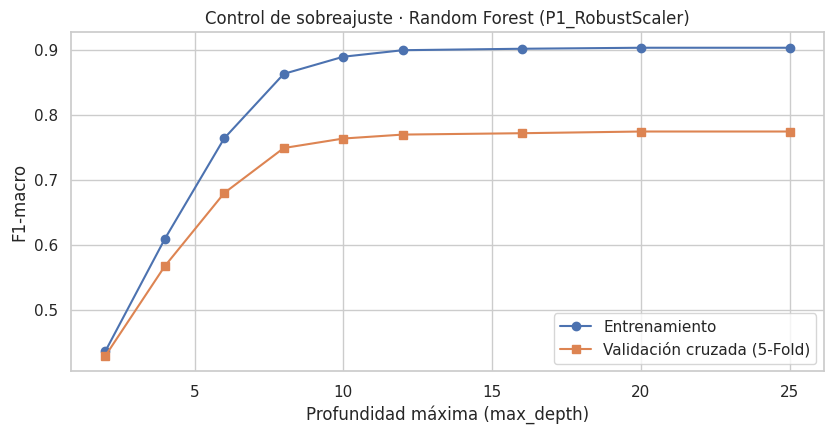

In [23]:
# Curva de validación de Random Forest al variar max_depth (control de sobreajuste)
profundidades = [2, 4, 6, 8, 10, 12, 16, 20, 25]
pipe_curva_rf = clone(mejor_rf)
pipe_curva_rf.set_params(clf__n_estimators=250)

tr_scores, val_scores = validation_curve(
    pipe_curva_rf, X_train, y_train,
    param_name="clf__max_depth", param_range=profundidades,
    cv=cv_5, scoring="f1_macro", n_jobs=-1,
)

plt.figure(figsize=(8.5, 4.5))
plt.plot(profundidades, tr_scores.mean(axis=1), marker="o", label="Entrenamiento")
plt.plot(profundidades, val_scores.mean(axis=1), marker="s", label="Validación cruzada (5-Fold)")
plt.xlabel("Profundidad máxima (max_depth)")
plt.ylabel("F1-macro")
plt.title(f"Control de sobreajuste · Random Forest ({MEJOR_PREP_RF})")
plt.legend()
plt.tight_layout()
plt.show()

M1_RandomForest + P1_RobustScaler (Preventivo (sin Gender)) -> CV=0.7375 | Test F1=0.7347 | 116.3 s
M1_RandomForest + P1_RobustScaler (Operativo (con Peso/Altura/IMC)) -> CV=0.9851 | Test F1=0.9853 | 119.3 s


,Modelo,Preprocesamiento,Benchmark,CV F1-macro,Train Accuracy,Test Accuracy,Brecha Train-Test,Test F1-macro,Tiempo fit (s),Latencia test (ms),ms / muestra,Tamaño (.pkl KB),Estructura
0,M1_RandomForest,P1_RobustScaler,Preventivo,0.7749 ± 0.0143,0.889,0.789,0.100,0.782,0.934,109.957,0.263,"9,955.700",350 árboles · 83650 nodos
1,M1_RandomForest,P1_RobustScaler,Preventivo (sin Gender),0.7375 ± 0.0076,0.874,0.744,0.130,0.735,0.787,76.037,0.182,"7,115.800",250 árboles · 59750 nodos
2,M1_RandomForest,P1_RobustScaler,Operativo (con Peso/Altura/IMC),0.9851 ± 0.0042,0.999,0.986,0.014,0.985,1.092,117.749,0.282,"9,046.800",350 árboles · 75894 nodos



Reporte por clase · M1 Random Forest (P1_RobustScaler):

              precision    recall  f1-score   support

 Peso insuf.      0.807     0.868     0.836        53
      Normal      0.640     0.561     0.598        57
 Sobrepeso I      0.741     0.727     0.734        55
Sobrepeso II      0.760     0.655     0.704        58
  Obesidad I      0.800     0.743     0.770        70
 Obesidad II      0.766     0.983     0.861        60
Obesidad III      0.969     0.969     0.969        65

    accuracy                          0.789       418
   macro avg      0.783     0.787     0.782       418
weighted avg      0.787     0.789     0.785       418



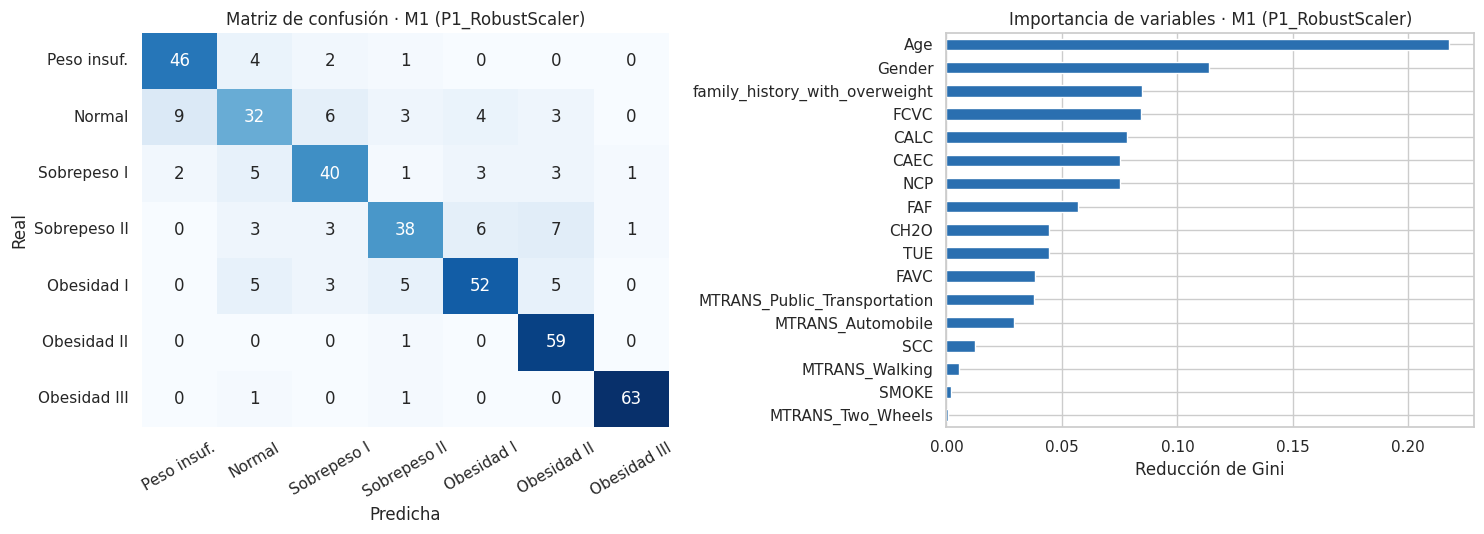

In [24]:
# Controles científicos de M1: 1) Sin Gender (sesgo SMOTE) y 2) Operativo (fuga de IMC)
X_tr_sg = X_train.drop(columns=["Gender"])
X_te_sg = X_test.drop(columns=["Gender"])

if MEJOR_PREP_RF == "P1_RobustScaler":
    prep_rf_sg = RobustScaler()
elif MEJOR_PREP_RF == "P2_Habitos_YeoJohnson":
    prep_rf_sg = construir_p2(X_tr_sg)
else:
    prep_rf_sg = crear_p3()

rf_sin_gender, res_rf_sg = evaluar_modelo(
    "M1_RandomForest", MEJOR_PREP_RF,
    Pipeline([("prep", prep_rf_sg), ("clf", RandomForestClassifier(random_state=SEMILLA, n_jobs=-1))]),
    param_rf, X_tr_sg, y_train, X_te_sg, y_test, benchmark="Preventivo (sin Gender)",
)

rf_oper, res_rf_oper = evaluar_modelo(
    "M1_RandomForest", "P1_RobustScaler",
    Pipeline([("prep", RobustScaler()), ("clf", RandomForestClassifier(random_state=SEMILLA, n_jobs=-1))]),
    param_rf, X_train_oper, y_train, X_test_oper, y_test, benchmark="Operativo (con Peso/Altura/IMC)",
)

tabla_controles_rf = pd.DataFrame([tabla_rf.loc[idx_best_rf].to_dict(), res_rf_sg, res_rf_oper])
display(tabla_controles_rf.drop(columns=["CV_media", "Hiperparámetros"]))

# Reporte por clase, matriz de confusión e importancia de variables del mejor M1
y_pred_rf = mejor_rf.predict(X_test)
print(f"\nReporte por clase · M1 Random Forest ({MEJOR_PREP_RF}):\n")
print(classification_report(y_test, y_pred_rf, target_names=etiquetas_clases, digits=3))

nombres_rf = list(mejor_rf.named_steps["prep"].get_feature_names_out())
imp_rf = pd.Series(mejor_rf.named_steps["clf"].feature_importances_, index=nombres_rf).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=etiquetas_clases, yticklabels=etiquetas_clases, ax=axes[0])
axes[0].set_title(f"Matriz de confusión · M1 ({MEJOR_PREP_RF})")
axes[0].set_xlabel("Predicha")
axes[0].set_ylabel("Real")
axes[0].tick_params(axis="x", rotation=30)

imp_rf.plot(kind="barh", ax=axes[1], color="#2a6fb0")
axes[1].set_title(f"Importancia de variables · M1 ({MEJOR_PREP_RF})")
axes[1].set_xlabel("Reducción de Gini")
plt.tight_layout()
plt.show()

---
# Paso 6 · Modelo M2: XGBoost (`XGBClassifier`)

Ensamble secuencial por **Gradient Boosting** que entrena árboles aditivos para las $K = 7$ clases minimizando la entropía cruzada con regularización $L_1$/$L_2$.

| Fase | Complejidad teórica (Big-O) | Explicación |
| :--- | :---: | :--- |
| **Entrenamiento** | $\mathcal{O}(T \cdot K \cdot d \cdot h \cdot n)$ | Construcción secuencial por histogramas (`hist`) en $T \cdot K$ árboles. |
| **Inferencia (1 muestra)** | $\mathcal{O}(T \cdot K \cdot h)$ | Recorrido raíz → hoja en los $T \cdot K$ árboles y *softmax*. |
| **Memoria** | $\mathcal{O}(T \cdot K \cdot N_{\text{nodos}})$ | Almacena nodos y pesos de hojas de cada árbol. |

In [25]:
param_xgb = {
    "clf__n_estimators": [100, 200, 300, 400],
    "clf__max_depth": [3, 4, 5, 6, 8],
    "clf__learning_rate": [0.03, 0.05, 0.1, 0.2],
    "clf__subsample": [0.7, 0.85, 1.0],
    "clf__colsample_bytree": [0.6, 0.8, 1.0],
    "clf__min_child_weight": [1, 3, 5],
    "clf__reg_alpha": [0.0, 0.1, 0.5, 1.0],
    "clf__reg_lambda": [0.5, 1.0, 2.0, 5.0],
}


def nuevo_xgb():
    return XGBClassifier(
        objective="multi:softprob",
        eval_metric="mlogloss",
        tree_method="hist",
        random_state=SEMILLA,
        n_jobs=1,
    )


# Entrenar XGBoost con los 3 preprocesamientos (P1, P2 y P3)
pipe_xgb_p1 = Pipeline([("prep", RobustScaler()), ("clf", nuevo_xgb())])
xgb_p1, res_xgb_p1 = evaluar_modelo("M2_XGBoost", "P1_RobustScaler", pipe_xgb_p1, param_xgb, X_train, y_train, X_test, y_test)

pipe_xgb_p2 = Pipeline([("prep", construir_p2(X_train)), ("clf", nuevo_xgb())])
xgb_p2, res_xgb_p2 = evaluar_modelo("M2_XGBoost", "P2_Habitos_YeoJohnson", pipe_xgb_p2, param_xgb, X_train, y_train, X_test, y_test)

pipe_xgb_p3 = Pipeline([("prep", crear_p3()), ("clf", nuevo_xgb())])
xgb_p3, res_xgb_p3 = evaluar_modelo("M2_XGBoost", "P3_Robust_PCA95", pipe_xgb_p3, param_xgb, X_train, y_train, X_test, y_test)

tabla_xgb = pd.DataFrame([res_xgb_p1, res_xgb_p2, res_xgb_p3])
display(tabla_xgb.drop(columns=["CV_media", "Hiperparámetros"]))

# Escoger el mejor preprocesamiento para M2 según validación cruzada
modelos_xgb = {"P1_RobustScaler": xgb_p1, "P2_Habitos_YeoJohnson": xgb_p2, "P3_Robust_PCA95": xgb_p3}
idx_best_xgb = tabla_xgb["CV_media"].idxmax()
MEJOR_PREP_XGB = tabla_xgb.loc[idx_best_xgb, "Preprocesamiento"]
mejor_xgb = modelos_xgb[MEJOR_PREP_XGB]
print("Mejor preprocesamiento para M2 (XGBoost):", MEJOR_PREP_XGB)

M2_XGBoost + P1_RobustScaler (Preventivo) -> CV=0.7942 | Test F1=0.8203 | 84.3 s
M2_XGBoost + P2_Habitos_YeoJohnson (Preventivo) -> CV=0.7943 | Test F1=0.7939 | 91.7 s
M2_XGBoost + P3_Robust_PCA95 (Preventivo) -> CV=0.7589 | Test F1=0.7518 | 231.7 s


,Modelo,Preprocesamiento,Benchmark,CV F1-macro,Train Accuracy,Test Accuracy,Brecha Train-Test,Test F1-macro,Tiempo fit (s),Latencia test (ms),ms / muestra,Tamaño (.pkl KB),Estructura
0,M2_XGBoost,P1_RobustScaler,Preventivo,0.7942 ± 0.0154,0.959,0.823,0.136,0.820,0.747,20.615,0.049,"3,976.900",1400 árboles · 92332 nodos
1,M2_XGBoost,P2_Habitos_YeoJohnson,Preventivo,0.7943 ± 0.0114,0.994,0.797,0.197,0.794,0.692,23.881,0.057,"3,444.500",1400 árboles · 76212 nodos
2,M2_XGBoost,P3_Robust_PCA95,Preventivo,0.7589 ± 0.0166,0.998,0.754,0.244,0.752,1.236,14.681,0.035,"2,242.800",1400 árboles · 40038 nodos


Mejor preprocesamiento para M2 (XGBoost): P2_Habitos_YeoJohnson


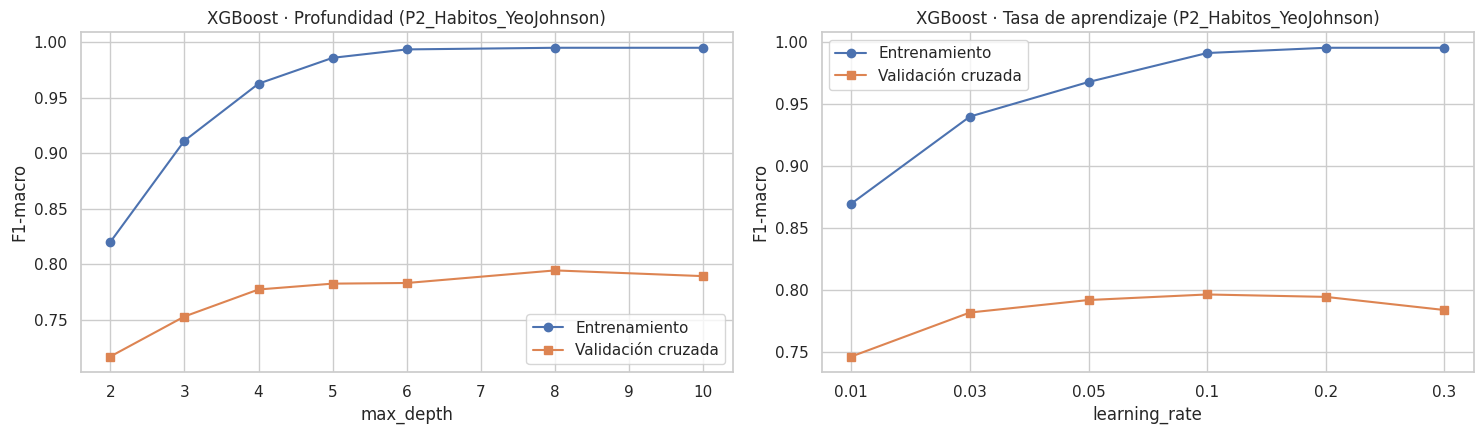

In [26]:
# Curvas de validación de XGBoost: max_depth y learning_rate
pipe_curva_xgb = clone(mejor_xgb).set_params(clf__n_jobs=1)

profundidades_xgb = [2, 3, 4, 5, 6, 8, 10]
tasas_xgb = [0.01, 0.03, 0.05, 0.1, 0.2, 0.3]

tr_d, val_d = validation_curve(
    clone(pipe_curva_xgb), X_train, y_train,
    param_name="clf__max_depth", param_range=profundidades_xgb,
    cv=cv_5, scoring="f1_macro", n_jobs=-1,
)
tr_lr, val_lr = validation_curve(
    clone(pipe_curva_xgb), X_train, y_train,
    param_name="clf__learning_rate", param_range=tasas_xgb,
    cv=cv_5, scoring="f1_macro", n_jobs=-1,
)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

axes[0].plot(profundidades_xgb, tr_d.mean(axis=1), marker="o", label="Entrenamiento")
axes[0].plot(profundidades_xgb, val_d.mean(axis=1), marker="s", label="Validación cruzada")
axes[0].set_xlabel("max_depth")
axes[0].set_ylabel("F1-macro")
axes[0].set_title(f"XGBoost · Profundidad ({MEJOR_PREP_XGB})")
axes[0].legend()

axes[1].plot(range(len(tasas_xgb)), tr_lr.mean(axis=1), marker="o", label="Entrenamiento")
axes[1].plot(range(len(tasas_xgb)), val_lr.mean(axis=1), marker="s", label="Validación cruzada")
axes[1].set_xticks(range(len(tasas_xgb)), [str(t) for t in tasas_xgb])
axes[1].set_xlabel("learning_rate")
axes[1].set_ylabel("F1-macro")
axes[1].set_title(f"XGBoost · Tasa de aprendizaje ({MEJOR_PREP_XGB})")
axes[1].legend()

plt.tight_layout()
plt.show()

M2_XGBoost + P2_Habitos_YeoJohnson (Preventivo (sin Gender)) -> CV=0.7604 | Test F1=0.7867 | 89.5 s
M2_XGBoost + P1_RobustScaler (Operativo (con Peso/Altura/IMC)) -> CV=0.9814 | Test F1=0.9879 | 66.0 s


,Modelo,Preprocesamiento,Benchmark,CV F1-macro,Train Accuracy,Test Accuracy,Brecha Train-Test,Test F1-macro,Tiempo fit (s),Latencia test (ms),ms / muestra,Tamaño (.pkl KB),Estructura
0,M2_XGBoost,P2_Habitos_YeoJohnson,Preventivo,0.7943 ± 0.0114,0.994,0.797,0.197,0.794,0.692,23.881,0.057,"3,444.500",1400 árboles · 76212 nodos
1,M2_XGBoost,P2_Habitos_YeoJohnson,Preventivo (sin Gender),0.7604 ± 0.0098,0.987,0.789,0.198,0.787,2.334,22.878,0.055,"3,240.100",2100 árboles · 56544 nodos
2,M2_XGBoost,P1_RobustScaler,Operativo (con Peso/Altura/IMC),0.9814 ± 0.0052,1.000,0.988,0.012,0.988,0.849,17.434,0.042,"2,378.700",2100 árboles · 30684 nodos



Reporte por clase · M2 XGBoost (P2_Habitos_YeoJohnson):

              precision    recall  f1-score   support

 Peso insuf.      0.857     0.792     0.824        53
      Normal      0.679     0.667     0.673        57
 Sobrepeso I      0.707     0.745     0.726        55
Sobrepeso II      0.683     0.707     0.695        58
  Obesidad I      0.765     0.743     0.754        70
 Obesidad II      0.889     0.933     0.911        60
Obesidad III      0.984     0.969     0.977        65

    accuracy                          0.797       418
   macro avg      0.795     0.794     0.794       418
weighted avg      0.798     0.797     0.797       418



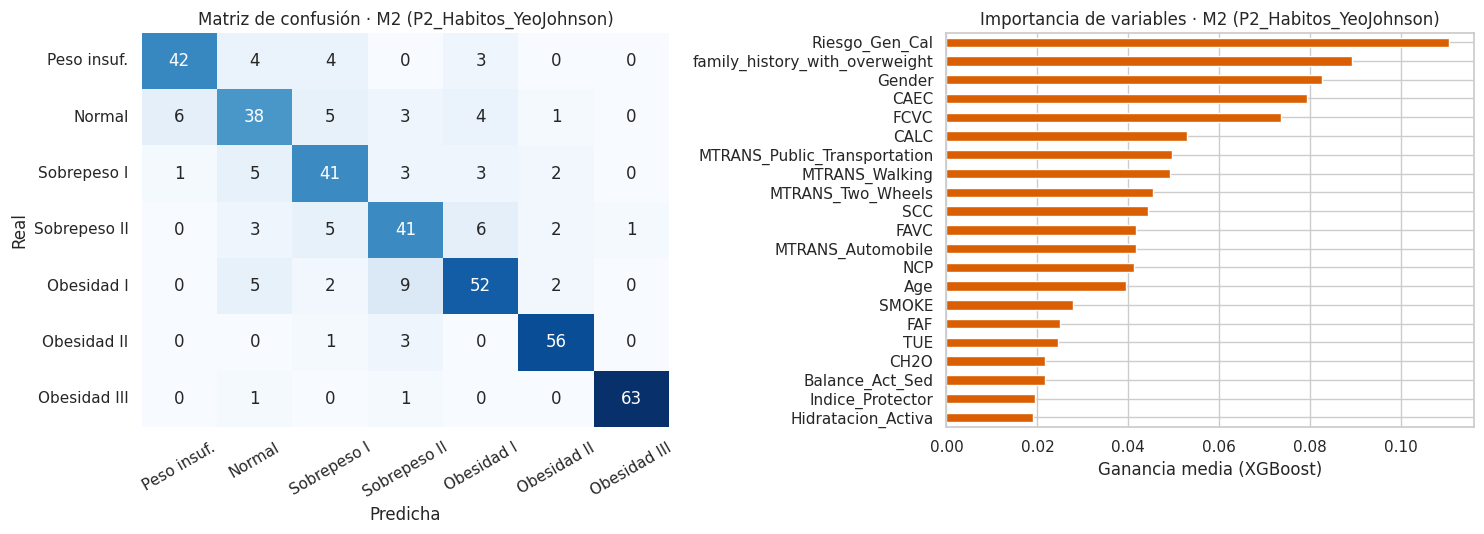

In [27]:
# Controles científicos de M2: 1) Sin Gender y 2) Operativo (con IMC)
if MEJOR_PREP_XGB == "P1_RobustScaler":
    prep_xgb_sg = RobustScaler()
elif MEJOR_PREP_XGB == "P2_Habitos_YeoJohnson":
    prep_xgb_sg = construir_p2(X_tr_sg)
else:
    prep_xgb_sg = crear_p3()

xgb_sin_gender, res_xgb_sg = evaluar_modelo(
    "M2_XGBoost", MEJOR_PREP_XGB,
    Pipeline([("prep", prep_xgb_sg), ("clf", nuevo_xgb())]),
    param_xgb, X_tr_sg, y_train, X_te_sg, y_test, benchmark="Preventivo (sin Gender)",
)

xgb_oper, res_xgb_oper = evaluar_modelo(
    "M2_XGBoost", "P1_RobustScaler",
    Pipeline([("prep", RobustScaler()), ("clf", nuevo_xgb())]),
    param_xgb, X_train_oper, y_train, X_test_oper, y_test, benchmark="Operativo (con Peso/Altura/IMC)",
)

tabla_controles_xgb = pd.DataFrame([tabla_xgb.loc[idx_best_xgb].to_dict(), res_xgb_sg, res_xgb_oper])
display(tabla_controles_xgb.drop(columns=["CV_media", "Hiperparámetros"]))

# Reporte por clase, matriz de confusión e importancia por ganancia
y_pred_xgb = mejor_xgb.predict(X_test)
print(f"\nReporte por clase · M2 XGBoost ({MEJOR_PREP_XGB}):\n")
print(classification_report(y_test, y_pred_xgb, target_names=etiquetas_clases, digits=3))

nombres_xgb = list(mejor_xgb.named_steps["prep"].get_feature_names_out())
imp_xgb = pd.Series(mejor_xgb.named_steps["clf"].feature_importances_, index=nombres_xgb).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(confusion_matrix(y_test, y_pred_xgb), annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=etiquetas_clases, yticklabels=etiquetas_clases, ax=axes[0])
axes[0].set_title(f"Matriz de confusión · M2 ({MEJOR_PREP_XGB})")
axes[0].set_xlabel("Predicha")
axes[0].set_ylabel("Real")
axes[0].tick_params(axis="x", rotation=30)

imp_xgb.plot(kind="barh", ax=axes[1], color="#d95f02")
axes[1].set_title(f"Importancia de variables · M2 ({MEJOR_PREP_XGB})")
axes[1].set_xlabel("Ganancia media (XGBoost)")
plt.tight_layout()
plt.show()

---
# Paso 7 · Modelo M3: Red Neuronal Multicapa (`MLPClassifier`)

Red densa con activación **ReLU**, optimizador **Adam**, penalización $L_2$ (`alpha`) y parada temprana (*early stopping*).

| Fase | Complejidad teórica (Big-O) | Explicación |
| :--- | :---: | :--- |
| **Entrenamiento** | $\mathcal{O}(E \cdot n \cdot W)$ | $E$ épocas sobre $n$ muestras actualizando $W$ pesos. |
| **Inferencia (1 muestra)** | $\mathcal{O}(W)$ | Multiplicaciones matriciales capa por capa. |
| **Memoria** | $\mathcal{O}(W)$ | Pesos, sesgos y estados del optimizador Adam. |

In [28]:
param_mlp = {
    "clf__hidden_layer_sizes": [(32,), (64,), (128,), (64, 32), (128, 64), (256, 128), (128, 64, 32)],
    "clf__alpha": [1e-5, 1e-4, 1e-3, 1e-2, 0.1, 0.5],
    "clf__learning_rate_init": [1e-3, 3e-3, 1e-2, 3e-2],
    "clf__batch_size": [16, 32, 64, 128],
}


def nuevo_mlp(semilla=SEMILLA):
    return MLPClassifier(
        activation="relu",
        solver="adam",
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=30,
        max_iter=1000,
        random_state=semilla,
    )


# Entrenar MLP con los 3 preprocesamientos (P1, P2 y P3)
pipe_mlp_p1 = Pipeline([("prep", RobustScaler()), ("clf", nuevo_mlp())])
mlp_p1, res_mlp_p1 = evaluar_modelo("M3_MLP", "P1_RobustScaler", pipe_mlp_p1, param_mlp, X_train, y_train, X_test, y_test)

pipe_mlp_p2 = Pipeline([("prep", construir_p2(X_train)), ("clf", nuevo_mlp())])
mlp_p2, res_mlp_p2 = evaluar_modelo("M3_MLP", "P2_Habitos_YeoJohnson", pipe_mlp_p2, param_mlp, X_train, y_train, X_test, y_test)

pipe_mlp_p3 = Pipeline([("prep", crear_p3()), ("clf", nuevo_mlp())])
mlp_p3, res_mlp_p3 = evaluar_modelo("M3_MLP", "P3_Robust_PCA95", pipe_mlp_p3, param_mlp, X_train, y_train, X_test, y_test)

tabla_mlp = pd.DataFrame([res_mlp_p1, res_mlp_p2, res_mlp_p3])
display(tabla_mlp.drop(columns=["CV_media", "Hiperparámetros"]))

# Escoger el mejor preprocesamiento para M3 según validación cruzada
modelos_mlp = {"P1_RobustScaler": mlp_p1, "P2_Habitos_YeoJohnson": mlp_p2, "P3_Robust_PCA95": mlp_p3}
idx_best_mlp = tabla_mlp["CV_media"].idxmax()
MEJOR_PREP_MLP = tabla_mlp.loc[idx_best_mlp, "Preprocesamiento"]
mejor_mlp = modelos_mlp[MEJOR_PREP_MLP]
print("Mejor preprocesamiento para M3 (MLP):", MEJOR_PREP_MLP)

M3_MLP + P1_RobustScaler (Preventivo) -> CV=0.7421 | Test F1=0.7564 | 305.9 s
M3_MLP + P2_Habitos_YeoJohnson (Preventivo) -> CV=0.7491 | Test F1=0.7518 | 307.0 s
M3_MLP + P3_Robust_PCA95 (Preventivo) -> CV=0.7381 | Test F1=0.7362 | 306.3 s


,Modelo,Preprocesamiento,Benchmark,CV F1-macro,Train Accuracy,Test Accuracy,Brecha Train-Test,Test F1-macro,Tiempo fit (s),Latencia test (ms),ms / muestra,Tamaño (.pkl KB),Estructura
0,M3_MLP,P1_RobustScaler,Preventivo,0.7421 ± 0.0134,0.927,0.766,0.161,0.756,9.128,10.600,0.025,911.000,"capas (256, 128) · 38407 pesos · 72 épocas"
1,M3_MLP,P2_Habitos_YeoJohnson,Preventivo,0.7491 ± 0.0027,0.860,0.756,0.104,0.752,3.526,11.303,0.027,937.300,"capas (256, 128) · 39431 pesos · 44 épocas"
2,M3_MLP,P3_Robust_PCA95,Preventivo,0.7381 ± 0.0177,0.950,0.744,0.206,0.736,3.065,3.748,0.009,298.200,"capas (128, 64, 32) · 12103 pesos · 101 épocas"


Mejor preprocesamiento para M3 (MLP): P2_Habitos_YeoJohnson


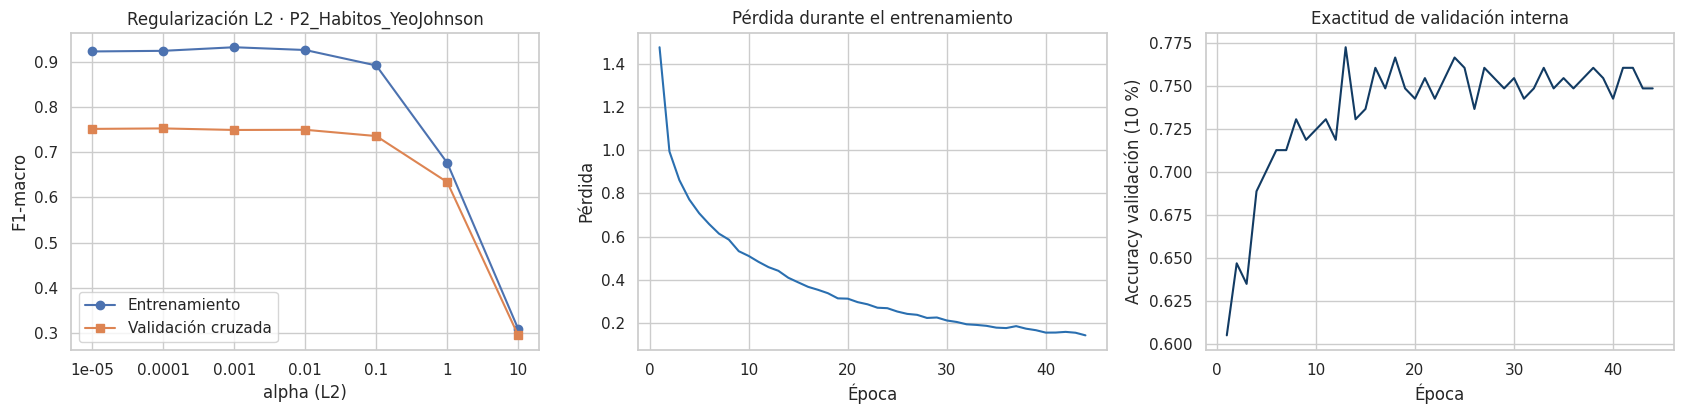

In [29]:
# Curvas de control de M3: regularización alpha y evolución por épocas (early stopping)
alphas = [1e-5, 1e-4, 1e-3, 1e-2, 0.1, 1.0, 10.0]
tr_a, val_a = validation_curve(
    clone(mejor_mlp), X_train, y_train,
    param_name="clf__alpha", param_range=alphas,
    cv=cv_5, scoring="f1_macro", n_jobs=-1,
)

mlp_clf = mejor_mlp.named_steps["clf"]
epocas = range(1, mlp_clf.n_iter_ + 1)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))

axes[0].plot(range(len(alphas)), tr_a.mean(axis=1), marker="o", label="Entrenamiento")
axes[0].plot(range(len(alphas)), val_a.mean(axis=1), marker="s", label="Validación cruzada")
axes[0].set_xticks(range(len(alphas)), [f"{a:g}" for a in alphas])
axes[0].set_xlabel("alpha (L2)")
axes[0].set_ylabel("F1-macro")
axes[0].set_title(f"Regularización L2 · {MEJOR_PREP_MLP}")
axes[0].legend()

axes[1].plot(epocas, mlp_clf.loss_curve_, color="#2a6fb0")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Pérdida")
axes[1].set_title("Pérdida durante el entrenamiento")

axes[2].plot(epocas, mlp_clf.validation_scores_, color="#123b63")
axes[2].set_xlabel("Época")
axes[2].set_ylabel("Accuracy validación (10 %)")
axes[2].set_title("Exactitud de validación interna")

plt.tight_layout()
plt.show()

M3_MLP + P2_Habitos_YeoJohnson (Preventivo (sin Gender)) -> CV=0.7120 | Test F1=0.7153 | 287.2 s
M3_MLP + P1_RobustScaler (Operativo (con Peso/Altura/IMC)) -> CV=0.9642 | Test F1=0.9586 | 273.8 s


,Modelo,Preprocesamiento,Benchmark,CV F1-macro,Train Accuracy,Test Accuracy,Brecha Train-Test,Test F1-macro,Tiempo fit (s),Latencia test (ms),ms / muestra,Tamaño (.pkl KB),Estructura
0,M3_MLP,P2_Habitos_YeoJohnson,Preventivo,0.7491 ± 0.0027,0.860,0.756,0.104,0.752,3.526,11.303,0.027,937.300,"capas (256, 128) · 39431 pesos · 44 épocas"
1,M3_MLP,P2_Habitos_YeoJohnson,Preventivo (sin Gender),0.7120 ± 0.0117,0.785,0.723,0.062,0.715,3.183,11.502,0.028,931.100,"capas (256, 128) · 39175 pesos · 39 épocas"
2,M3_MLP,P1_RobustScaler,Operativo (con Peso/Altura/IMC),0.9642 ± 0.0068,0.995,0.959,0.035,0.959,6.148,3.108,0.007,321.200,"capas (128, 64, 32) · 13255 pesos · 49 épocas"



Reporte por clase · M3 MLP (P2_Habitos_YeoJohnson):

              precision    recall  f1-score   support

 Peso insuf.      0.900     0.849     0.874        53
      Normal      0.596     0.596     0.596        57
 Sobrepeso I      0.627     0.673     0.649        55
Sobrepeso II      0.660     0.569     0.611        58
  Obesidad I      0.716     0.686     0.701        70
 Obesidad II      0.789     0.933     0.855        60
Obesidad III      0.984     0.969     0.977        65

    accuracy                          0.756       418
   macro avg      0.753     0.754     0.752       418
weighted avg      0.756     0.756     0.754       418



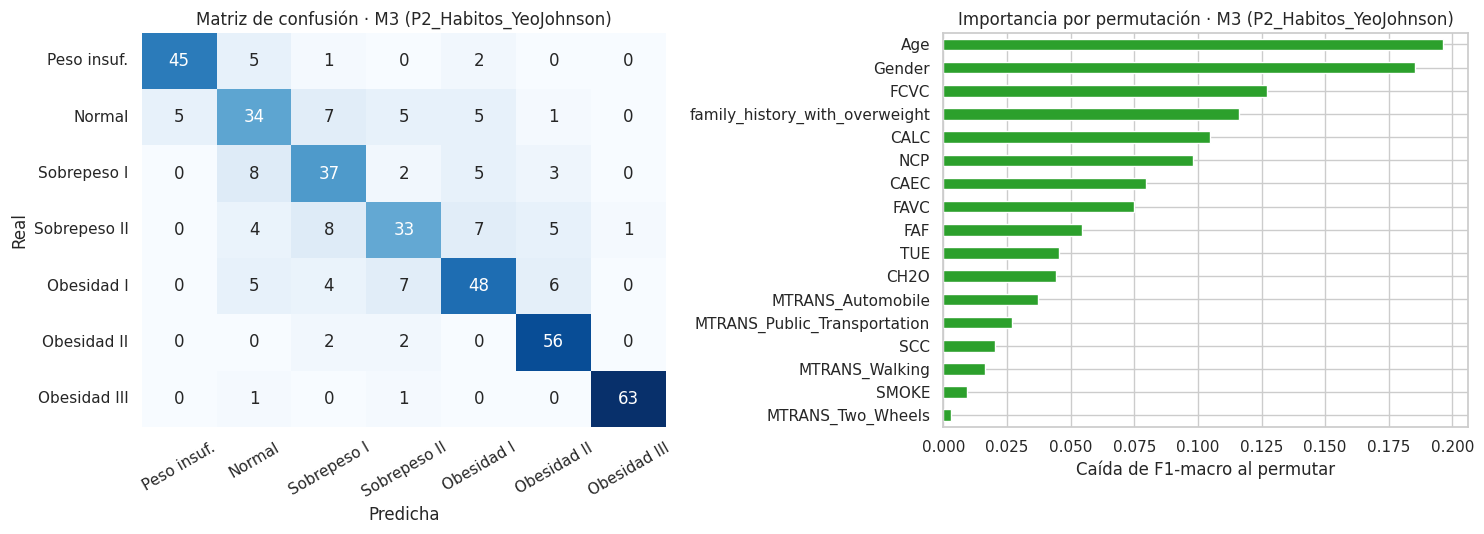

Estabilidad M3 (10 semillas) -> media=0.7592 | desv=0.0116 | min=0.7439 | max=0.7769


In [30]:
# Controles científicos de M3: 1) Sin Gender y 2) Operativo (con IMC)
if MEJOR_PREP_MLP == "P1_RobustScaler":
    prep_mlp_sg = RobustScaler()
elif MEJOR_PREP_MLP == "P2_Habitos_YeoJohnson":
    prep_mlp_sg = construir_p2(X_tr_sg)
else:
    prep_mlp_sg = crear_p3()

mlp_sin_gender, res_mlp_sg = evaluar_modelo(
    "M3_MLP", MEJOR_PREP_MLP,
    Pipeline([("prep", prep_mlp_sg), ("clf", nuevo_mlp())]),
    param_mlp, X_tr_sg, y_train, X_te_sg, y_test, benchmark="Preventivo (sin Gender)",
)

mlp_oper, res_mlp_oper = evaluar_modelo(
    "M3_MLP", "P1_RobustScaler",
    Pipeline([("prep", RobustScaler()), ("clf", nuevo_mlp())]),
    param_mlp, X_train_oper, y_train, X_test_oper, y_test, benchmark="Operativo (con Peso/Altura/IMC)",
)

tabla_controles_mlp = pd.DataFrame([tabla_mlp.loc[idx_best_mlp].to_dict(), res_mlp_sg, res_mlp_oper])
display(tabla_controles_mlp.drop(columns=["CV_media", "Hiperparámetros"]))

# Reporte por clase, matriz de confusión e importancia por permutación
y_pred_mlp = mejor_mlp.predict(X_test)
print(f"\nReporte por clase · M3 MLP ({MEJOR_PREP_MLP}):\n")
print(classification_report(y_test, y_pred_mlp, target_names=etiquetas_clases, digits=3))

perm = permutation_importance(mejor_mlp, X_test, y_test, scoring="f1_macro", n_repeats=20, random_state=SEMILLA, n_jobs=-1)
imp_mlp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(confusion_matrix(y_test, y_pred_mlp), annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=etiquetas_clases, yticklabels=etiquetas_clases, ax=axes[0])
axes[0].set_title(f"Matriz de confusión · M3 ({MEJOR_PREP_MLP})")
axes[0].set_xlabel("Predicha")
axes[0].set_ylabel("Real")
axes[0].tick_params(axis="x", rotation=30)

imp_mlp.plot(kind="barh", ax=axes[1], color="#2ca02c")
axes[1].set_title(f"Importancia por permutación · M3 ({MEJOR_PREP_MLP})")
axes[1].set_xlabel("Caída de F1-macro al permutar")
plt.tight_layout()
plt.show()

# Prueba rápida de estabilidad ante 10 semillas diferentes
f1_semillas = []
for s in [SEMILLA] + list(range(9)):
    m_s = clone(mejor_mlp).set_params(clf__random_state=s).fit(X_train, y_train)
    f1_semillas.append(f1_score(y_test, m_s.predict(X_test), average="macro"))
print(f"Estabilidad M3 (10 semillas) -> media={np.mean(f1_semillas):.4f} | desv={np.std(f1_semillas):.4f} | min={np.min(f1_semillas):.4f} | max={np.max(f1_semillas):.4f}")

---
# Paso 8 · Matriz Consolidada $3 \times 3$, Complejidad y Exportación del Ganador

Reunimos los 9 experimentos preventivos (`3 modelos × 3 preprocesamientos`) y los 6 controles en una sola tabla, graficamos el compromiso entre precisión y costo computacional, y guardamos el modelo ganador en Drive para la aplicación de despliegue.

=== Matriz 3×3 Preventiva (ordenada por Test F1-macro) ===


,Modelo,Preprocesamiento,Benchmark,CV F1-macro,Train Accuracy,Test Accuracy,Brecha Train-Test,Test F1-macro,Tiempo fit (s),Latencia test (ms),ms / muestra,Tamaño (.pkl KB),Estructura
3,M2_XGBoost,P1_RobustScaler,Preventivo,0.7942 ± 0.0154,0.959,0.823,0.136,0.820,0.747,20.615,0.049,"3,976.900",1400 árboles · 92332 nodos
4,M2_XGBoost,P2_Habitos_YeoJohnson,Preventivo,0.7943 ± 0.0114,0.994,0.797,0.197,0.794,0.692,23.881,0.057,"3,444.500",1400 árboles · 76212 nodos
0,M1_RandomForest,P1_RobustScaler,Preventivo,0.7749 ± 0.0143,0.889,0.789,0.100,0.782,0.934,109.957,0.263,"9,955.700",350 árboles · 83650 nodos
2,M1_RandomForest,P3_Robust_PCA95,Preventivo,0.7505 ± 0.0216,0.934,0.766,0.169,0.760,1.603,109.016,0.261,"9,958.300",350 árboles · 83650 nodos
6,M3_MLP,P1_RobustScaler,Preventivo,0.7421 ± 0.0134,0.927,0.766,0.161,0.756,9.128,10.600,0.025,911.000,"capas (256, 128) · 38407 pesos · 72 épocas"
1,M1_RandomForest,P2_Habitos_YeoJohnson,Preventivo,0.7638 ± 0.0209,0.891,0.766,0.125,0.755,0.842,82.802,0.198,"7,122.700",250 árboles · 59750 nodos
5,M2_XGBoost,P3_Robust_PCA95,Preventivo,0.7589 ± 0.0166,0.998,0.754,0.244,0.752,1.236,14.681,0.035,"2,242.800",1400 árboles · 40038 nodos
7,M3_MLP,P2_Habitos_YeoJohnson,Preventivo,0.7491 ± 0.0027,0.860,0.756,0.104,0.752,3.526,11.303,0.027,937.300,"capas (256, 128) · 39431 pesos · 44 épocas"
8,M3_MLP,P3_Robust_PCA95,Preventivo,0.7381 ± 0.0177,0.950,0.744,0.206,0.736,3.065,3.748,0.009,298.200,"capas (128, 64, 32) · 12103 pesos · 101 épocas"



=== Controles Científicos (sin Gender y Operativo) ===


,Modelo,Preprocesamiento,Benchmark,CV F1-macro,Train Accuracy,Test Accuracy,Brecha Train-Test,Test F1-macro,Tiempo fit (s),Latencia test (ms),ms / muestra,Tamaño (.pkl KB),Estructura
0,M1_RandomForest,P1_RobustScaler,Preventivo (sin Gender),0.7375 ± 0.0076,0.874,0.744,0.130,0.735,0.787,76.037,0.182,"7,115.800",250 árboles · 59750 nodos
1,M1_RandomForest,P1_RobustScaler,Operativo (con Peso/Altura/IMC),0.9851 ± 0.0042,0.999,0.986,0.014,0.985,1.092,117.749,0.282,"9,046.800",350 árboles · 75894 nodos
2,M2_XGBoost,P2_Habitos_YeoJohnson,Preventivo (sin Gender),0.7604 ± 0.0098,0.987,0.789,0.198,0.787,2.334,22.878,0.055,"3,240.100",2100 árboles · 56544 nodos
3,M2_XGBoost,P1_RobustScaler,Operativo (con Peso/Altura/IMC),0.9814 ± 0.0052,1.000,0.988,0.012,0.988,0.849,17.434,0.042,"2,378.700",2100 árboles · 30684 nodos
4,M3_MLP,P2_Habitos_YeoJohnson,Preventivo (sin Gender),0.7120 ± 0.0117,0.785,0.723,0.062,0.715,3.183,11.502,0.028,931.100,"capas (256, 128) · 39175 pesos · 39 épocas"
5,M3_MLP,P1_RobustScaler,Operativo (con Peso/Altura/IMC),0.9642 ± 0.0068,0.995,0.959,0.035,0.959,6.148,3.108,0.007,321.200,"capas (128, 64, 32) · 13255 pesos · 49 épocas"


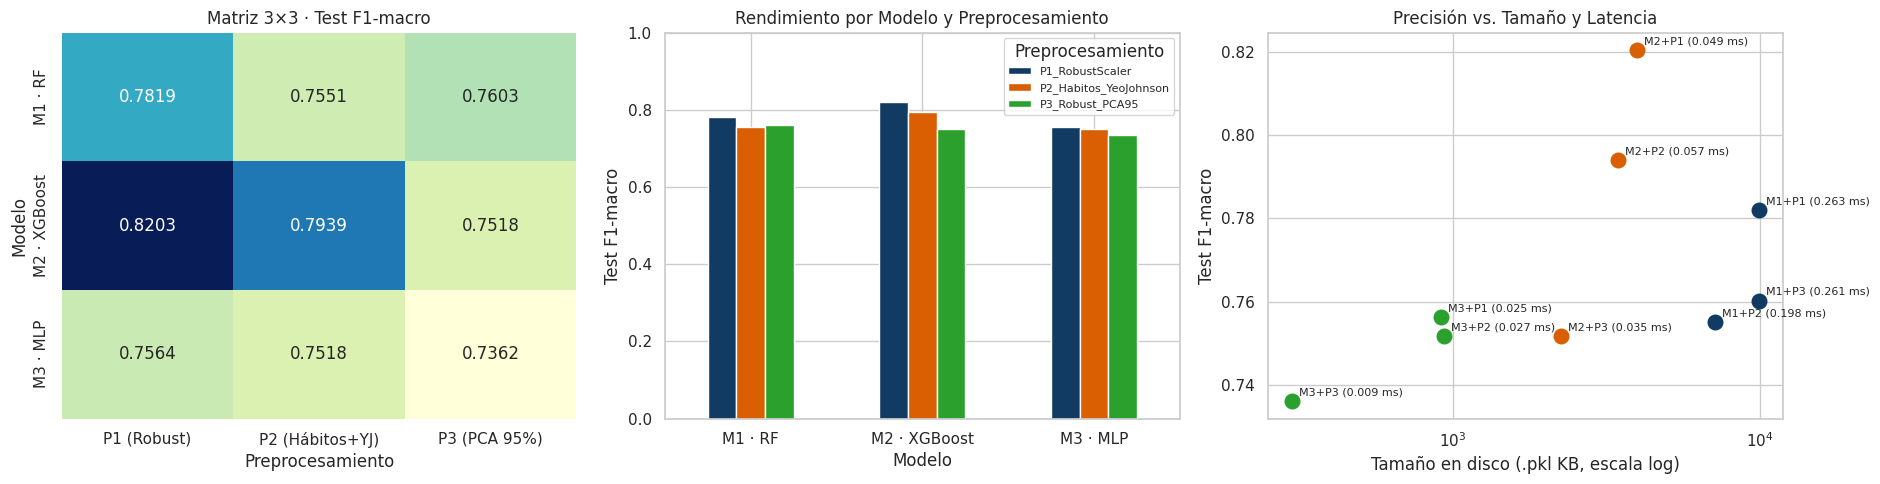

In [31]:
cols_tabla = [
    "Modelo", "Preprocesamiento", "Benchmark", "CV F1-macro",
    "Train Accuracy", "Test Accuracy", "Brecha Train-Test", "Test F1-macro",
    "Tiempo fit (s)", "Latencia test (ms)", "ms / muestra", "Tamaño (.pkl KB)", "Estructura",
]

tabla_prev_3x3 = pd.concat([tabla_rf, tabla_xgb, tabla_mlp], ignore_index=True)
tabla_controles_all = pd.concat([
    tabla_controles_rf.iloc[1:],
    tabla_controles_xgb.iloc[1:],
    tabla_controles_mlp.iloc[1:],
], ignore_index=True)
tabla_completa = pd.concat([tabla_prev_3x3, tabla_controles_all], ignore_index=True)

print("=== Matriz 3×3 Preventiva (ordenada por Test F1-macro) ===")
display(tabla_prev_3x3[cols_tabla].sort_values("Test F1-macro", ascending=False))

print("\n=== Controles Científicos (sin Gender y Operativo) ===")
display(tabla_controles_all[cols_tabla])

# Gráfica comparativa de 3 paneles: Heatmap 3x3 | Barras | Trade-off memoria/latencia
orden_m = ["M1_RandomForest", "M2_XGBoost", "M3_MLP"]
orden_p = ["P1_RobustScaler", "P2_Habitos_YeoJohnson", "P3_Robust_PCA95"]
piv_f1 = tabla_prev_3x3.pivot(index="Modelo", columns="Preprocesamiento", values="Test F1-macro").loc[orden_m, orden_p]

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

sns.heatmap(
    piv_f1, annot=True, fmt=".4f", cmap="YlGnBu", cbar=False, ax=axes[0],
    xticklabels=["P1 (Robust)", "P2 (Hábitos+YJ)", "P3 (PCA 95%)"],
    yticklabels=["M1 · RF", "M2 · XGBoost", "M3 · MLP"],
)
axes[0].set_title("Matriz 3×3 · Test F1-macro")

piv_f1.plot(kind="bar", ax=axes[1], color=["#123b63", "#d95f02", "#2ca02c"], edgecolor="white")
axes[1].set_ylim(0, 1.0)
axes[1].set_xticklabels(["M1 · RF", "M2 · XGBoost", "M3 · MLP"], rotation=0)
axes[1].set_ylabel("Test F1-macro")
axes[1].set_title("Rendimiento por Modelo y Preprocesamiento")
axes[1].legend(title="Preprocesamiento", fontsize=8)

colores_m = {"M1_RandomForest": "#123b63", "M2_XGBoost": "#d95f02", "M3_MLP": "#2ca02c"}
for _, fila in tabla_prev_3x3.iterrows():
    etq = fila["Modelo"].split("_")[0] + "+" + fila["Preprocesamiento"].split("_")[0]
    axes[2].scatter(fila["Tamaño (.pkl KB)"], fila["Test F1-macro"], s=110, color=colores_m[fila["Modelo"]])
    axes[2].annotate(f"{etq} ({fila['ms / muestra']:.3f} ms)", (fila["Tamaño (.pkl KB)"], fila["Test F1-macro"]),
                     textcoords="offset points", xytext=(5, 4), fontsize=8)
axes[2].set_xscale("log")
axes[2].set_xlabel("Tamaño en disco (.pkl KB, escala log)")
axes[2].set_ylabel("Test F1-macro")
axes[2].set_title("Precisión vs. Tamaño y Latencia")

plt.tight_layout()
plt.savefig(os.path.join(CARPETA_MODELOS, "matriz_3x3_comparativa.png"), dpi=180, bbox_inches="tight")
plt.show()

In [32]:
# Guardar todos los modelos (.pkl) y tablas (.csv) en Google Drive
todos_modelos = {
    "m1_rf_p1_robustscaler_preventivo.pkl": rf_p1,
    "m1_rf_p2_habitos_yeojohnson_preventivo.pkl": rf_p2,
    "m1_rf_p3_robust_pca95_preventivo.pkl": rf_p3,
    "m1_rf_sin_gender.pkl": rf_sin_gender,
    "m2_xgb_p1_robustscaler_preventivo.pkl": xgb_p1,
    "m2_xgb_p2_habitos_yeojohnson_preventivo.pkl": xgb_p2,
    "m2_xgb_p3_robust_pca95_preventivo.pkl": xgb_p3,
    "m2_xgb_sin_gender.pkl": xgb_sin_gender,
    "m3_mlp_p1_robustscaler_preventivo.pkl": mlp_p1,
    "m3_mlp_p2_habitos_yeojohnson_preventivo.pkl": mlp_p2,
    "m3_mlp_p3_robust_pca95_preventivo.pkl": mlp_p3,
    "m3_mlp_sin_gender.pkl": mlp_sin_gender,
}

for nombre_archivo, pipe_ent in todos_modelos.items():
    joblib.dump(pipe_ent, os.path.join(CARPETA_MODELOS, nombre_archivo))

pd.concat([tabla_rf, tabla_controles_rf.iloc[1:]], ignore_index=True).drop(columns=["CV_media"]).to_csv(
    os.path.join(CARPETA_MODELOS, "resultados_m1_rf.csv"), index=False
)
pd.concat([tabla_xgb, tabla_controles_xgb.iloc[1:]], ignore_index=True).drop(columns=["CV_media"]).to_csv(
    os.path.join(CARPETA_MODELOS, "resultados_m2_xgb.csv"), index=False
)
pd.concat([tabla_mlp, tabla_controles_mlp.iloc[1:]], ignore_index=True).drop(columns=["CV_media"]).to_csv(
    os.path.join(CARPETA_MODELOS, "resultados_m3_mlp.csv"), index=False
)
tabla_completa[cols_tabla].to_csv(os.path.join(CARPETA_MODELOS, "resultados_matriz_consolidada.csv"), index=False)

# Seleccionar automáticamente el modelo ganador según el mayor CV F1-macro (sin mirar el test)
idx_ganador = tabla_prev_3x3["CV_media"].idxmax()
fila_ganador = tabla_prev_3x3.loc[idx_ganador]
gan_modelo = fila_ganador["Modelo"]
gan_prep = fila_ganador["Preprocesamiento"]

mapa_ganador = {
    ("M1_RandomForest", "P1_RobustScaler"): rf_p1,
    ("M1_RandomForest", "P2_Habitos_YeoJohnson"): rf_p2,
    ("M1_RandomForest", "P3_Robust_PCA95"): rf_p3,
    ("M2_XGBoost", "P1_RobustScaler"): xgb_p1,
    ("M2_XGBoost", "P2_Habitos_YeoJohnson"): xgb_p2,
    ("M2_XGBoost", "P3_Robust_PCA95"): xgb_p3,
    ("M3_MLP", "P1_RobustScaler"): mlp_p1,
    ("M3_MLP", "P2_Habitos_YeoJohnson"): mlp_p2,
    ("M3_MLP", "P3_Robust_PCA95"): mlp_p3,
}
modelo_ganador = mapa_ganador[(gan_modelo, gan_prep)]

# Exportar modelo ganador y JSON de métricas (mismo esquema de la app de Semana 7)
joblib.dump(modelo_ganador, os.path.join(CARPETA_MODELOS, "modelo_ganador.pkl"))

metricas_ganador = {
    "algoritmo": str(gan_modelo),
    "preprocesamiento": str(gan_prep),
    "benchmark": "Preventivo",
    "accuracy": float(fila_ganador["Test Accuracy"]),
    "f1_macro": float(fila_ganador["Test F1-macro"]),
    "cv_f1_macro": str(fila_ganador["CV F1-macro"]),
    "tiempo_fit_s": float(fila_ganador["Tiempo fit (s)"]),
    "ms_por_muestra": float(fila_ganador["ms / muestra"]),
    "tamano_kb": float(fila_ganador["Tamaño (.pkl KB)"]),
    "hiperparametros": fila_ganador["Hiperparámetros"],
    "columnas": list(X_train.columns),
    "clases": {str(k): v for k, v in nombres_clases.items()},
    "rangos": {c: [float(X_train[c].min()), float(X_train[c].max())] for c in X_train.columns},
    "fecha": datetime.now().strftime("%Y-%m-%d %H:%M"),
}

with open(os.path.join(CARPETA_MODELOS, "metricas_ganador.json"), "w", encoding="utf-8") as f:
    json.dump(metricas_ganador, f, indent=2, ensure_ascii=False)

print(f"GANADOR FINAL POR CV: {gan_modelo} + {gan_prep}")
print(f"CV F1-macro: {fila_ganador['CV F1-macro']} | Test Accuracy: {fila_ganador['Test Accuracy']} | Test F1-macro: {fila_ganador['Test F1-macro']}")
print("Archivos guardados en:", CARPETA_MODELOS)

GANADOR FINAL POR CV: M2_XGBoost + P2_Habitos_YeoJohnson
CV F1-macro: 0.7943 ± 0.0114 | Test Accuracy: 0.7967 | Test F1-macro: 0.7939
Archivos guardados en: /content/drive/MyDrive/Proyecto_Final_Aprendizaje_Automatico/modelos


---
# Paso 9 · Selección Final del Mejor Modelo (Rendimiento, Estabilidad y Complejidad)

Para justificar de forma objetiva cuál es el mejor modelo según la rúbrica del curso, comparamos a los **3 finalistas** (`M1 · Random Forest`, `M2 · XGBoost` y `M3 · MLP`, cada uno con su mejor preprocesamiento en CV) en cuatro criterios:
1. **Métricas globales y probabilísticas** (`F1-macro`, `Precision`, `Recall`, `ROC-AUC OvR` y control `sin Gender`).
2. **Desempeño detallado por cada una de las 7 clases de obesidad.**
3. **Curvas de aprendizaje (`learning_curve`)** para evaluar sesgo/varianza y escalabilidad temporal al aumentar el número de datos $n$.
4. **Tabla de decisión final** integrando desempeño y complejidad computacional.

=== Tabla de Decisión Final · Comparación de los 3 Finalistas ===


,Modelo,Mejor Prep (CV),CV F1-macro,Test Accuracy,Test F1-macro,Precision macro,Recall macro,ROC-AUC (OvR),Brecha Tr-Te,F1 sin Gender,Fit (s),ms / muestra,Tamaño (KB)
0,M1 · Random Forest,P1_RobustScaler,0.7749 ± 0.0143,0.789,0.782,0.783,0.787,0.956,0.100,0.735,0.934,0.263,"9,955.700"
1,M2 · XGBoost,P2_Habitos_YeoJohnson,0.7943 ± 0.0114,0.797,0.794,0.795,0.794,0.964,0.197,0.787,0.692,0.057,"3,444.500"
2,M3 · MLP,P2_Habitos_YeoJohnson,0.7491 ± 0.0027,0.756,0.752,0.753,0.754,0.942,0.104,0.715,3.526,0.027,937.300


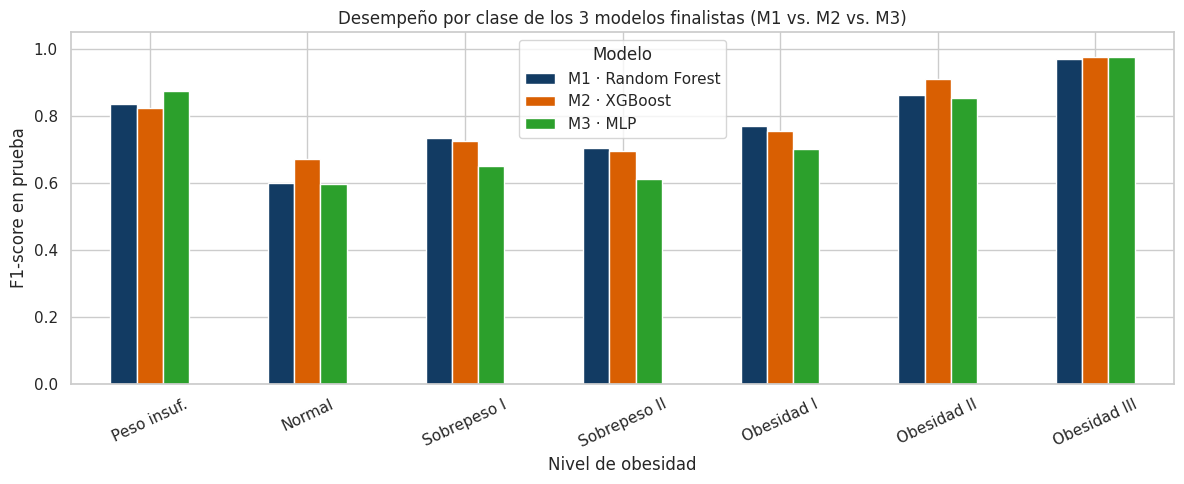

In [35]:
from sklearn.metrics import precision_score, recall_score, roc_auc_score
from sklearn.model_selection import learning_curve

# Los 3 modelos finalistas (cada uno con su mejor preprocesamiento según CV)
finalistas = [
    ("M1 · Random Forest", MEJOR_PREP_RF, mejor_rf, tabla_rf.loc[idx_best_rf], res_rf_sg),
    ("M2 · XGBoost", MEJOR_PREP_XGB, mejor_xgb, tabla_xgb.loc[idx_best_xgb], res_xgb_sg),
    ("M3 · MLP", MEJOR_PREP_MLP, mejor_mlp, tabla_mlp.loc[idx_best_mlp], res_mlp_sg),
]

filas_decision = []
f1_por_clase = {}

for nombre, prep, modelo, fila_cv, fila_sg in finalistas:
    y_pred = modelo.predict(X_test)
    y_prob = modelo.predict_proba(X_test)

    # Métricas complementarias en prueba
    prec = precision_score(y_test, y_pred, average="macro")
    rec = recall_score(y_test, y_pred, average="macro")
    roc_auc = roc_auc_score(y_test, y_prob, multi_class="ovr", average="macro")
    f1_por_clase[nombre] = f1_score(y_test, y_pred, average=None)

    filas_decision.append({
        "Modelo": nombre,
        "Mejor Prep (CV)": prep,
        "CV F1-macro": fila_cv["CV F1-macro"],
        "Test Accuracy": fila_cv["Test Accuracy"],
        "Test F1-macro": fila_cv["Test F1-macro"],
        "Precision macro": round(prec, 4),
        "Recall macro": round(rec, 4),
        "ROC-AUC (OvR)": round(roc_auc, 4),
        "Brecha Tr-Te": fila_cv["Brecha Train-Test"],
        "F1 sin Gender": fila_sg["Test F1-macro"],
        "Fit (s)": fila_cv["Tiempo fit (s)"],
        "ms / muestra": fila_cv["ms / muestra"],
        "Tamaño (KB)": fila_cv["Tamaño (.pkl KB)"],
    })

tabla_decision = pd.DataFrame(filas_decision)
tabla_decision.to_csv(os.path.join(CARPETA_MODELOS, "tabla_decision_finalistas.csv"), index=False)
print("=== Tabla de Decisión Final · Comparación de los 3 Finalistas ===")
display(tabla_decision)

# Gráfica comparativa de F1 por cada una de las 7 clases
df_clases = pd.DataFrame(f1_por_clase, index=etiquetas_clases)
ax = df_clases.plot(kind="bar", figsize=(12, 5), color=["#123b63", "#d95f02", "#2ca02c"], edgecolor="white")
ax.set_ylim(0, 1.05)
ax.set_ylabel("F1-score en prueba")
ax.set_xlabel("Nivel de obesidad")
ax.set_title("Desempeño por clase de los 3 modelos finalistas (M1 vs. M2 vs. M3)")
plt.xticks(rotation=25)
plt.legend(title="Modelo")
plt.tight_layout()
plt.savefig(os.path.join(CARPETA_MODELOS, "comparacion_f1_por_clase.png"), dpi=180, bbox_inches="tight")
plt.show()

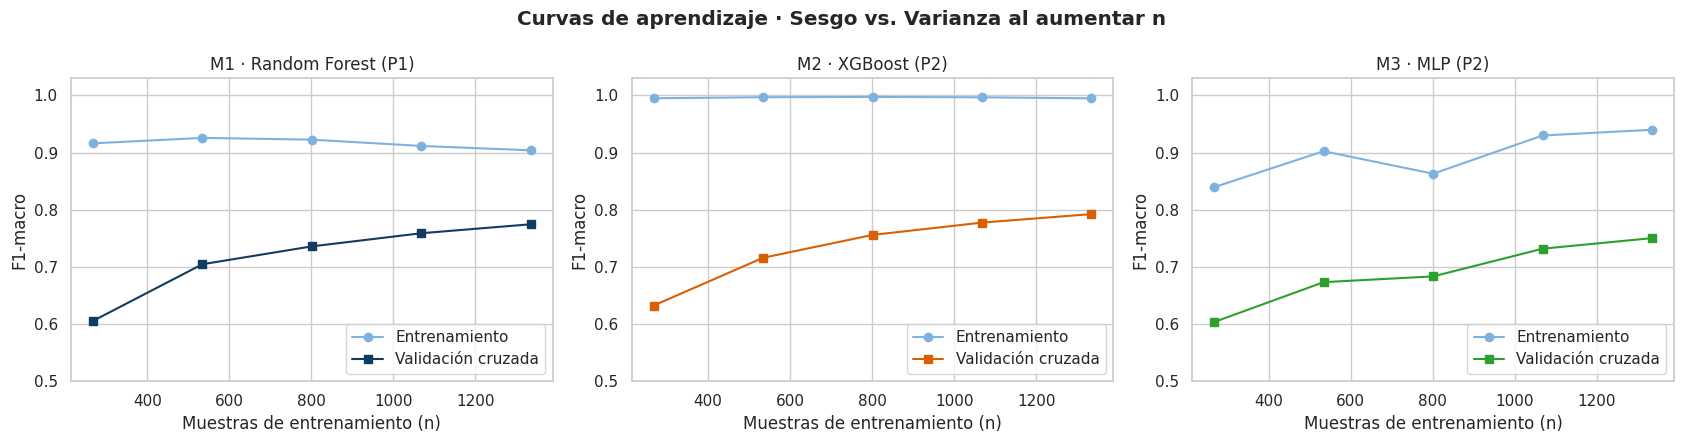

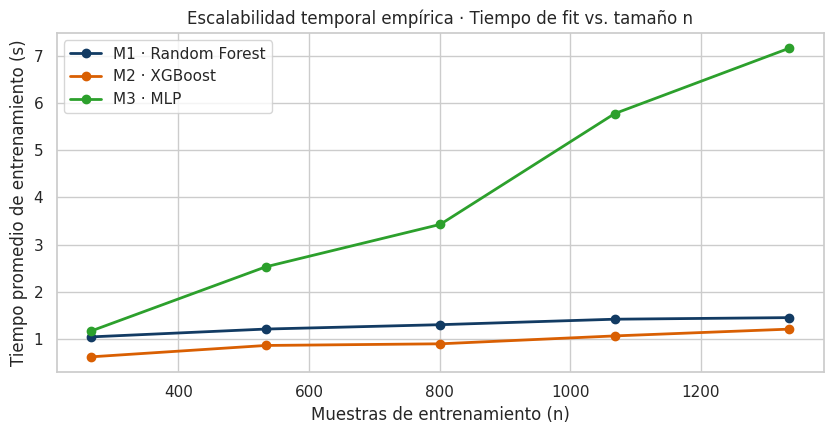

In [36]:
# Curvas de aprendizaje (F1-macro y tiempo de entrenamiento vs. tamaño de datos n)
fracciones = np.linspace(0.2, 1.0, 5)
colores_lc = {"M1 · Random Forest": "#123b63", "M2 · XGBoost": "#d95f02", "M3 · MLP": "#2ca02c"}

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
tiempos_n = {}
tamanos_ref = None

for ax, (nombre, prep, modelo, _, _) in zip(axes, finalistas):
    modelo_lc = clone(modelo)
    if "clf__n_jobs" in modelo_lc.get_params():
        modelo_lc.set_params(clf__n_jobs=1)

    tamanos, tr_s, val_s, fit_t, _ = learning_curve(
        modelo_lc, X_train, y_train,
        train_sizes=fracciones,
        cv=cv_5,
        scoring="f1_macro",
        return_times=True,
        n_jobs=-1,
    )
    tamanos_ref = tamanos
    tiempos_n[nombre] = fit_t.mean(axis=1)

    ax.plot(tamanos, tr_s.mean(axis=1), marker="o", color="#7fb1de", label="Entrenamiento")
    ax.plot(tamanos, val_s.mean(axis=1), marker="s", color=colores_lc[nombre], label="Validación cruzada")
    ax.set_ylim(0.5, 1.03)
    ax.set_xlabel("Muestras de entrenamiento (n)")
    ax.set_ylabel("F1-macro")
    ax.set_title(f"{nombre} ({prep.split('_')[0]})")
    ax.legend(loc="lower right")

plt.suptitle("Curvas de aprendizaje · Sesgo vs. Varianza al aumentar n", fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(CARPETA_MODELOS, "curvas_aprendizaje_finalistas.png"), dpi=180, bbox_inches="tight")
plt.show()

# Gráfica de escalabilidad temporal: cómo crece el tiempo de entrenamiento con n
plt.figure(figsize=(8.5, 4.5))
for nombre, t_medios in tiempos_n.items():
    plt.plot(tamanos_ref, t_medios, marker="o", lw=2, color=colores_lc[nombre], label=nombre)
plt.xlabel("Muestras de entrenamiento (n)")
plt.ylabel("Tiempo promedio de entrenamiento (s)")
plt.title("Escalabilidad temporal empírica · Tiempo de fit vs. tamaño n")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(CARPETA_MODELOS, "escalabilidad_tiempo_finalistas.png"), dpi=180, bbox_inches="tight")
plt.show()